<a href="https://colab.research.google.com/github/edwardptera/Ramman/blob/main/Raman.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Espectroscopía Raman**


<p style="text-align: justify;">
La espectroscopía Raman fue descubierta en 1928 por el físico indio C. V. Raman usando equipos ópticos muy sencillos. Descubrió que al chocar la luz con la materia, un pequeño porcentaje de los fotones intercambiaba energía con las moléculas, revelando la estructura interna de estas. Por este hallazgo ganó el Premio Nobel en 1930. Sin embargo, como el efecto era muy tenue, tardaba horas en medirse. Fue gracias a la invención del láser en la década de 1960 y los detectores modernos que el análisis Raman se convirtió en la potente herramienta instrumental que usamos hoy en día.
</p>

# 1. Introducción y estructura de los archivos CSV

In [1]:
# Librerías estándar de Python
from importlib.metadata import version
# installing RamanSPy library
%pip -q install ramanspy
print("RamanSPy se importó correctamente.")
print("Versión de RamanSPy:", version("ramanspy"))

RamanSPy se importó correctamente.
Versión de RamanSPy: 0.2.10


In [2]:
# Librerías científicas y de análisis de datos
import numpy as np
import pandas as pd
from scipy.signal import find_peaks
from scipy.integrate import trapezoid

# Librerías de espectroscopía especializadas
import ramanspy as rp

# Librerías de visualización gráfica
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Función auxiliar para renderizar texto en formato Markdown
def dMarkdown(text):
    return display(Markdown(text))

## 1.1 Espectro Raman de etanol - Shif Raman

### 1.1.1 Exploración del espectro de etanol original

Se explora primero el espectro Raman de etanol original para comprender la estructura del archivo CSV antes de aplicar cualquier procesamiento.

El conjunto de datos contiene el espectro Raman y una sección adicional llamada `Peaks`. El espectro está representado por el índice del DataFrame y los valores de intensidad almacenados en la columna `Unnamed: 0`.

Durante la exploración inicial, se realizan los siguientes pasos:

- Cargar el espectro Raman de etanol original.
- Inspeccionar la estructura y los tipos de datos del DataFrame.
- Identificar los valores no numéricos en el índice.
- Localizar la sección `Peaks`.
- Inspeccionar los datos antes y después de la etiqueta `Peaks`.
- Graficar los datos originales para comprender cómo se almacenan la información del espectro y de los picos.

Este paso exploratorio es importante porque la información de los picos se almacena después del espectro Raman original en el mismo archivo CSV. Los datos originales se mantienen sin cambios durante todo el análisis.


In [3]:
# Original ethanol Raman spectrum (Raman shift)
etanol = pd.read_csv("https://raw.githubusercontent.com/edwardptera/Ramman/refs/heads/main/data/etanol_20260924.csv")

# Original isopropsnol Raman spectrum (Raman shift)
isopropanol = pd.read_csv("https://raw.githubusercontent.com/edwardptera/Ramman/refs/heads/main/data/isopropilico_20261008.csv")

dMarkdown("### Etanol")
display(etanol.sample(10))
dMarkdown("### Isopropanol")
display(isopropanol.sample(10))

### Etanol

,Unnamed: 0
1199.46262823644,699.17830
1575.47630679043,622.31800
2900.9770395701,2723.63800
2634.19638495359,454.39790
2722.42305813385,718.22530
3860.9672691744,66.86666
722.618466047875,631.00010
4020.61553492916,66.86666
1037.71372740596,1214.82800
207.962872496336,3.72014


### Isopropanol

,Unnamed: 0
3865.16853932584,47.33333
1827.55251587689,479.05690
3440.84025403029,204.72740
1957.79189057157,448.40020
3413.53199804592,226.42970
2812.75036638984,401.99190
3075.32975085491,276.67110
689.008304836346,664.57310
201.660967269174,4.62235
172.252076209086,2.81797


In [4]:
display(etanol.head())
dMarkdown("#### Columnas:")
display(etanol.columns)

dMarkdown("#### Índice:")
display(etanol.index[:10])
dMarkdown("#### Info:")
display(etanol.info())

,Unnamed: 0
0,3893.405
2.10063507572057,3971.438
4.20127015144113,3915.907
6.3019052271617,3739.435
8.40254030288227,3402.577


#### Columnas:

Index(['Unnamed: 0'], dtype='object')

#### Índice:

Index(['0', '2.10063507572057', '4.20127015144113', '6.3019052271617',
       '8.40254030288227', '10.5031753786028', '12.6038104543234',
       '14.704445530044', '16.8050806057645', '18.9057156814851'],
      dtype='object')

#### Info:

<class 'pandas.core.frame.DataFrame'>
Index: 2064 entries, 0 to 3325.30532486566
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  2063 non-null   float64
dtypes: float64(1)
memory usage: 32.2+ KB


None

In [5]:
# Buscar valores no numéricos en el índice
indices_numericos = pd.to_numeric(etanol.index, errors="coerce")

# Mostrar las filas con valores de índice no numéricos
etanol[indices_numericos.isna()]

,Unnamed: 0
Peaks,NaN


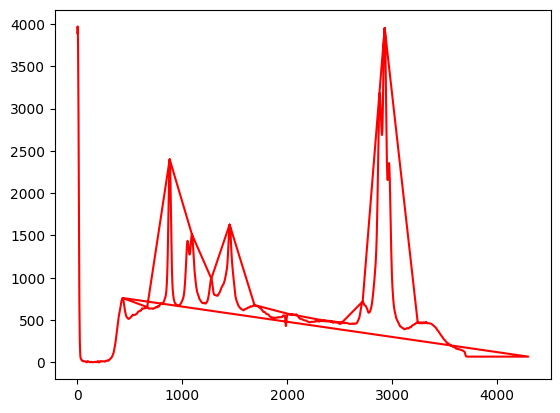

In [6]:
# Convertir el índice a valores numéricos
# Las entradas no numéricas, como "Peaks", se convierten en NaN
indices_numericos = pd.to_numeric(etanol.index, errors="coerce")

# Conservar solo las filas con valores numéricos de desplazamiento Raman
etanol_data = etanol[indices_numericos.notna()].copy()

# Eje X: Desplazamiento Raman (cm⁻¹)
x_etanol = indices_numericos[indices_numericos.notna()]

# Eje Y: Intensidad Raman
y_etanol = etanol_data["Unnamed: 0"]

plt.plot(x_etanol, y_etanol, color='red')
plt.show()

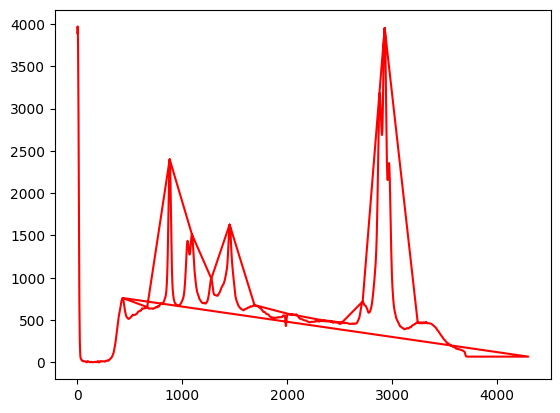

In [7]:
# X-axis: Raman shift (cm⁻¹) of the ethanol spectrum
x_etanol = pd.Series(
    indices_numericos[indices_numericos.notna()],
    name="Raman_Shift"
)

# Y-axis: Raman intensity of the ethanol spectrum
y_etanol = etanol_data["Unnamed: 0"].reset_index(drop=True)

# Reset the index of the Raman shift values
x_etanol = x_etanol.reset_index(drop=True)

plt.plot(x_etanol, y_etanol, color='red')
plt.show()

In [8]:
dMarkdown("#### Primeros valores del eje de Desplazamiento Raman (cm⁻¹):")
display(x_etanol.head())

dMarkdown("#### Primeros valores de la Intensidad Raman del etanol:")
display(y_etanol.head())

#### Primeros valores del eje de Desplazamiento Raman (cm⁻¹):

,Raman_Shift
0,0.000000
1,2.100635
2,4.201270
3,6.301905
4,8.402540


#### Primeros valores de la Intensidad Raman del etanol:

,Unnamed: 0
0,3893.405
1,3971.438
2,3915.907
3,3739.435
4,3402.577


In [9]:
# Formatear la información espectral del etanol usando f-strings
info_markdown = f"""
### Información del Espectro de Etanol

* **Número de puntos espectrales:** {len(x_etanol)}
* **Valores de intensidad ausentes:** {y_etanol.isna().sum()}
"""

# Mostrar el resultado renderizado en Markdown
dMarkdown(info_markdown)


### Información del Espectro de Etanol

* **Número de puntos espectrales:** 2063
* **Valores de intensidad ausentes:** 0


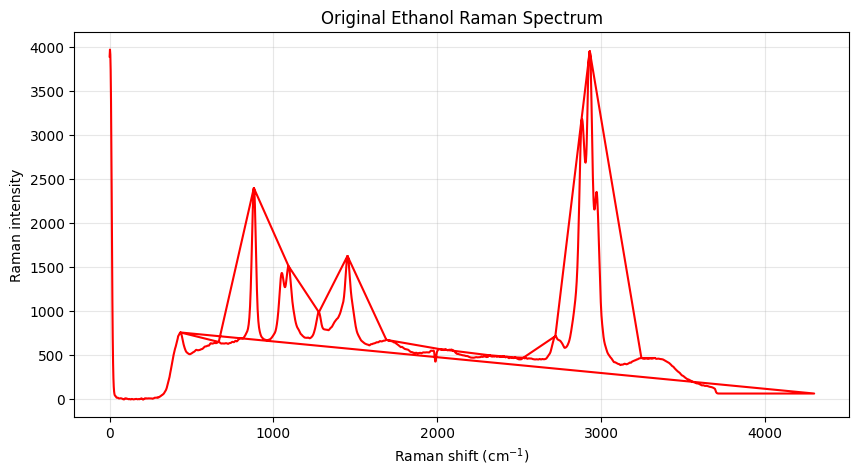

In [10]:
# Plot the original ethanol Raman spectrum
plt.figure(figsize=(10, 5))
plt.plot(x_etanol, y_etanol, color='red')
# Axis labels
plt.xlabel("Raman shift (cm$^{-1}$)")
plt.ylabel("Raman intensity")
# Plot title
plt.title("Original Ethanol Raman Spectrum")
# Add grid
plt.grid(True, alpha=0.3)
plt.show()

Como podemos ver, la anterior gráfica no está totalmente limpia, ya que aparece un poligono envolvente que involucra el valor de los picos, por lo tanto identiocaremos estos valores en el archivo .csv para eliminarlos de la gráfica.

In [11]:
# Display the last rows of the original ethanol DataFrame
display(etanol.tail(20))

,Unnamed: 0
4293.69809477284,66.866660
4295.79872984856,66.866660
4297.89936492428,66.866660
4300,66.866660
Peaks,NaN
432.730825598437,760.113953
665.90131900342,652.464539
880.166096726917,2400.254639
1092.33023937469,1511.969116
1277.1861260381,989.537476


In [12]:
# Find the position of "Peaks" in the index
peaks_position = list(etanol.index).index("Peaks")

# Display the rows around "Peaks"
display(etanol.iloc[peaks_position:peaks_position + 20])

,Unnamed: 0
Peaks,NaN
432.730825598437,760.113953
665.90131900342,652.464539
880.166096726917,2400.254639
1092.33023937469,1511.969116
1277.1861260381,989.537476
1451.53883732291,1628.242676
1688.91060087934,676.582397
2012.4084025403,572.044189
2317.00048851979,501.545074


### 1.1.2 Creación de un espectro Raman limpio

El archivo CSV de etanol original contiene el espectro Raman seguido de una sección separada llamada `Peaks`.

La sección `Peaks` contiene información sobre los picos detectados y no forma parte del espectro original.

Se crea un nuevo DataFrame llamado `etanol_clean` utilizando únicamente los datos espectrales. El DataFrame y el archivo CSV originales no se modifican.

El nuevo DataFrame contiene dos columnas:

- `Raman_Shift_cm-1`: desplazamiento Raman en cm⁻¹.
- `Intensity`: intensidad Raman.

In [13]:
# Encontrar la posición de la sección "Peaks"
peaks_position = list(etanol.index).index("Peaks")

# Conservar solo los datos del espectro Raman original
# antes de la sección "Peaks"
etanol_spectrum = etanol.iloc[:peaks_position].copy()

# Mostrar las últimas filas del espectro
display(etanol_spectrum.tail())

,Unnamed: 0
4291.59745969712,66.86666
4293.69809477284,66.86666
4295.79872984856,66.86666
4297.89936492428,66.86666
4300,66.86666


In [14]:
# X-axis: Raman shift
x_etanol = pd.Series(
    pd.to_numeric(etanol_spectrum.index),
    name="Wavenumber"
).reset_index(drop=True)

# Y-axis: Raman intensity
y_etanol = etanol_spectrum["Unnamed: 0"].reset_index(drop=True)

dMarkdown("### Wavenumber")
display(x_etanol.head())
dMarkdown("### Counts")
display(y_etanol.head())

### Wavenumber

,Wavenumber
0,0.000000
1,2.100635
2,4.201270
3,6.301905
4,8.402540


### Counts

,Unnamed: 0
0,3893.405
1,3971.438
2,3915.907
3,3739.435
4,3402.577


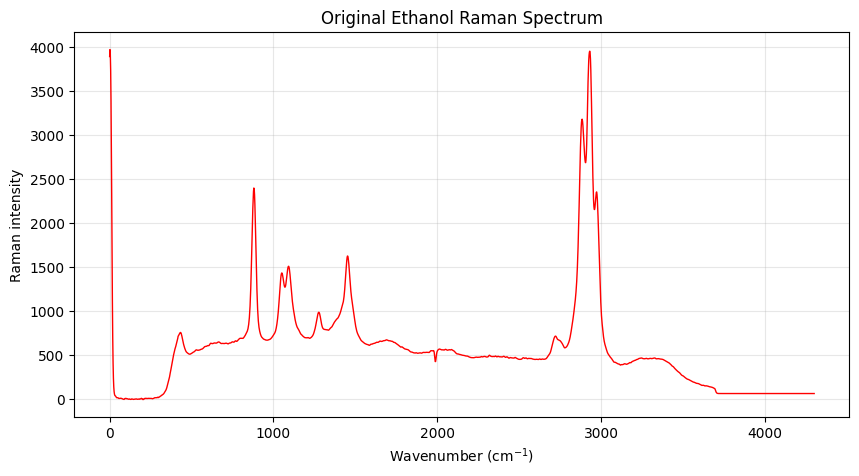

In [15]:
# Graficar el espectro Raman limpio y original del etanol
plt.figure(figsize=(10, 5))

plt.plot(x_etanol, y_etanol, linewidth=1, color = 'red')

# Etiquetas de los ejes
plt.xlabel("Wavenumber (cm$^{-1}$)")
plt.ylabel("Raman intensity")

# Título del gráfico
plt.title("Original Ethanol Raman Spectrum")

# Añadir cuadrícula
plt.grid(True, alpha=0.3)

plt.show()

In [16]:
# Mostrar información básica sobre el espectro de etanol usando f-strings y dMarkdown

info_espectro = f"""
### Información Básica del Espectro de Etanol

* **Número de puntos espectrales:** {len(x_etanol)}
* **Número de onda mínimo:** {x_etanol.min():.1f} cm$^{{-1}}$
* **Número de onda máximo:** {x_etanol.max():.1f} cm$^{{-1}}$
* **Valores de intensidad ausentes:** {y_etanol.isna().sum()}
"""

dMarkdown(info_espectro)


### Información Básica del Espectro de Etanol

* **Número de puntos espectrales:** 2048
* **Número de onda mínimo:** 0.0 cm$^{-1}$
* **Número de onda máximo:** 4300.0 cm$^{-1}$
* **Valores de intensidad ausentes:** 0


In [17]:
# Crear un DataFrame limpio para el espectro Raman de etanol
etanol_clean = pd.DataFrame({
    "Wavenumber_cm-1": x_etanol,
    "Intensity": y_etanol
})

# Construir y renderizar la información de salida de forma estética
salida_etanol = f"""
### Primeras Filas del Espectro Limpio de Etanol

{etanol_clean.head().to_markdown(index=False)}
"""

dMarkdown(salida_etanol)


### Primeras Filas del Espectro Limpio de Etanol

|   Wavenumber_cm-1 |   Intensity |
|------------------:|------------:|
|           0       |     3893.41 |
|           2.10064 |     3971.44 |
|           4.20127 |     3915.91 |
|           6.30191 |     3739.43 |
|           8.40254 |     3402.58 |


### 1.1.3 Extracción de la información de los picos

El archivo CSV de etanol original contiene una sección `Peaks` después del espectro Raman.

Esta sección contiene la posición y la intensidad de los picos detectados. La información de los picos se extrae en un nuevo DataFrame llamado `etanol_peaks`.

El DataFrame original no se modifica.

In [18]:
# Encontrar la posición de la sección "Peaks"
peaks_position = list(etanol.index).index("Peaks")

# Extraer los datos de los picos después de la etiqueta "Peaks"
etanol_peaks = etanol.iloc[peaks_position + 1:].copy()

# Renombrar la columna de intensidad
etanol_peaks = etanol_peaks.rename(
    columns={"Unnamed: 0": "Peak_Intensity"}
)

# Convertir el índice a valores numéricos
etanol_peaks.index = pd.to_numeric(etanol_peaks.index)

# Asignar un nombre descriptivo al índice
etanol_peaks.index.name = "Peak_Wavenumber_cm-1"

# Mostrar el DataFrame de picos
display(etanol_peaks)

,Peak_Intensity
Peak_Wavenumber_cm-1,
432.730826,760.113953
665.901319,652.464539
880.166097,2400.254639
1092.330239,1511.969116
1277.186126,989.537476
1451.538837,1628.242676
1688.910601,676.582397
2012.408403,572.044189
2317.000489,501.545074


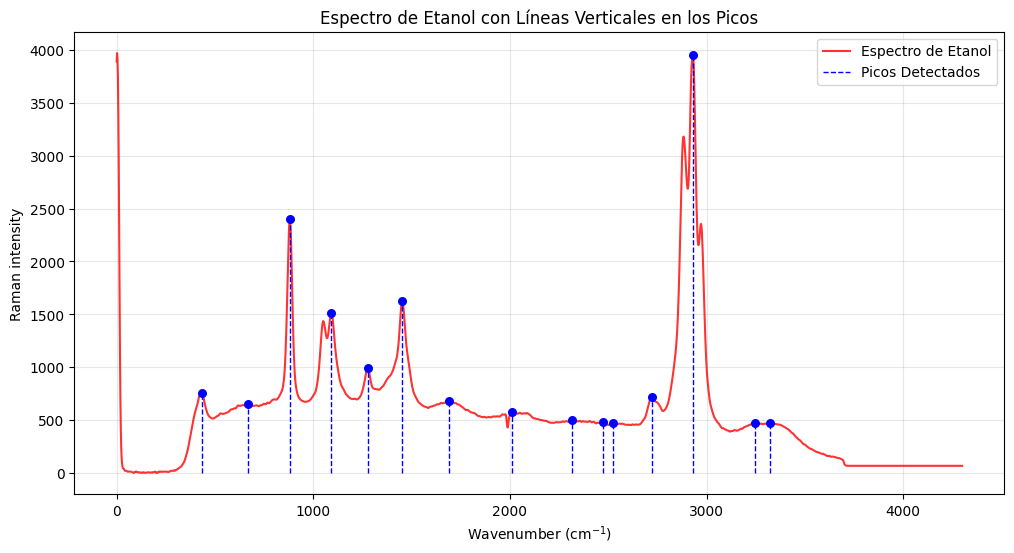

In [19]:
# Graficar el espectro de etanol mostrando la ubicación de los picos con líneas verticales (vlines)
plt.figure(figsize=(12, 6))

# Dibujar la señal continua del espectro limpio
plt.plot(etanol_clean["Wavenumber_cm-1"], etanol_clean["Intensity"], color="red", label="Espectro de Etanol", alpha=0.8)

# Dibujar líneas verticales en cada una de las posiciones de los picos detectados
plt.vlines(
    x=etanol_peaks.index,
    ymin=0,
    ymax=etanol_peaks["Peak_Intensity"],
    color="blue",
    linestyle="--",
    linewidth=1,
    label="Picos Detectados"
)

# Dibujar puntos en la punta de cada pico
plt.scatter(
    etanol_peaks.index,
    etanol_peaks["Peak_Intensity"],
    color="blue",
    s=30,
    zorder=3
)

# Etiquetas de los ejes y título
plt.xlabel("Wavenumber (cm$^{-1}$)")
plt.ylabel("Raman intensity")
plt.title("Espectro de Etanol con Líneas Verticales en los Picos")
plt.grid(True, alpha=0.3)
plt.legend()

plt.show()

# 2. Automatización del proceso

Ahora vamos a realizar nuevamente el proceso anterior, pero automatizando el código, es decir, haciéndolo más versátil y reutilizable para los diferentes espectros Raman.

Como vimos en el espectro Raman del etanol en función del corrimiento Raman, el archivo `.csv` contiene también información sobre los picos detectados por el software. Por lo tanto, es necesario separar estos datos de las mediciones espectrales para evitar que aparezcan en la gráfica del espectro.

En esta sección se desarrollará una función que permita realizar este proceso de manera automática, facilitando su aplicación a los diferentes archivos `.csv`.

## 2.1 Espectro Raman de etanol - Shif Raman

In [20]:
def process_raman_csv(df):
    """
    Procesa un archivo CSV de Raman que contiene un espectro
    seguido de una sección de picos (Peaks).

    Retorna:
        spectrum: Espectro Raman limpio
        peaks: Posiciones e intensidades de los picos detectados
    """

    # Encontrar la posición de la sección "Peaks"
    peaks_position = list(df.index).index("Peaks")

    # Extraer el espectro antes de la sección de picos
    spectrum = df.iloc[:peaks_position].copy()

    # Extraer los datos de los picos después de la sección "Peaks"
    peaks = df.iloc[peaks_position + 1:].copy()

    # Convertir el índice del espectro a valores numéricos
    spectrum.index = pd.to_numeric(spectrum.index)

    # Convertir el índice de los picos a valores numéricos
    peaks.index = pd.to_numeric(peaks.index)

    # Renombrar las columnas de intensidad
    spectrum = spectrum.rename(
        columns={"Unnamed: 0": "Intensity"}
    )

    peaks = peaks.rename(
        columns={"Unnamed: 0": "Peak_Intensity"}
    )

    # Renombrar los índices
    spectrum.index.name = "X"
    peaks.index.name = "Peak_Position"

    return spectrum, peaks

In [21]:
# Process the original ethanol Raman spectrum

etanol_clean, etanol_peaks = process_raman_csv(etanol)

dMarkdown("### Clean ethanol spectrum:")
display(etanol_clean.head())

dMarkdown("### Ethanol peaks:")
display(etanol_peaks)

### Clean ethanol spectrum:

,Intensity
X,
0.000000,3893.405
2.100635,3971.438
4.201270,3915.907
6.301905,3739.435
8.402540,3402.577


### Ethanol peaks:

,Peak_Intensity
Peak_Position,
432.730826,760.113953
665.901319,652.464539
880.166097,2400.254639
1092.330239,1511.969116
1277.186126,989.537476
1451.538837,1628.242676
1688.910601,676.582397
2012.408403,572.044189
2317.000489,501.545074


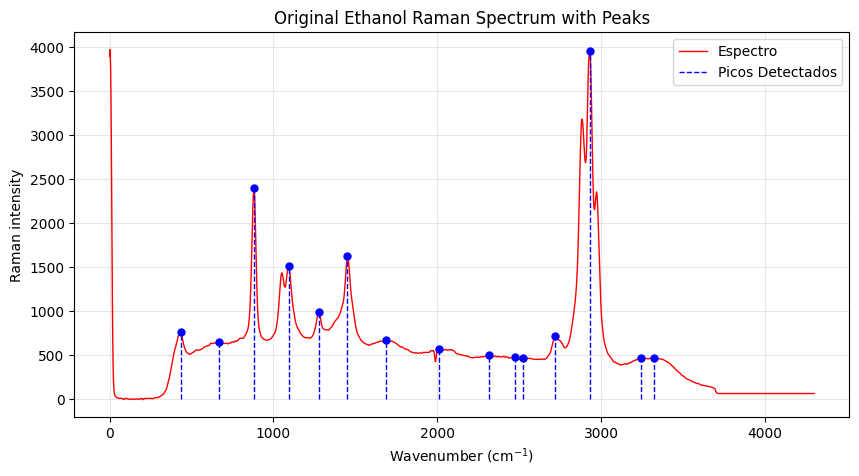

In [22]:
def plot_raman_spectrum(
    spectrum,
    peaks=None,
    title="Espectro Raman",
    x_label="Wavenumber (cm$^{-1}$)"
    ):
    """
    Grafica un espectro Raman limpio utilizando los valores del eje X
    y la intensidad Raman, marcando opcionalmente los picos con líneas verticales (vlines).
    """
    # Crear la figura y los ejes
    fig, ax = plt.subplots(figsize=(10, 5))

    # Graficar el espectro continuo
    ax.plot(
        spectrum.index,
        spectrum["Intensity"],
        linewidth=1,
        color="red",
        label="Espectro"
    )

    # Si se proporcionan picos, graficarlos con vlines y marcadores puntuales
    if peaks is not None:
        # Dibujar líneas verticales desde el eje X hasta la intensidad del pico
        ax.vlines(
            x=peaks.index,
            ymin=0,
            ymax=peaks["Peak_Intensity"],
            colors="blue",
            linestyles="--",
            linewidths=1,
            label="Picos Detectados"
        )
        # Dibujar puntos en los máximos de los picos
        ax.scatter(
            peaks.index,
            peaks["Peak_Intensity"],
            color="blue",
            s=25,
            zorder=3
        )
        ax.legend()

    # Etiquetas de los ejes
    ax.set_xlabel(x_label)
    ax.set_ylabel("Raman intensity")

    # Título del gráfico
    ax.set_title(title)

    # Añadir cuadrícula
    ax.grid(True, alpha=0.3)

    # Mostrar el gráfico
    plt.show()

# Probar la función actualizada con el espectro y picos de etanol
plot_raman_spectrum(
    etanol_clean,
    peaks=etanol_peaks,
    title="Original Ethanol Raman Spectrum with Peaks",
    x_label="Wavenumber (cm$^{-1}$)"
)

 ## 2.2 Espectro Raman del isopropanol - Shif Raman

In [23]:
# Explora el espectro Raman original del isopropanol

dMarkdown("### isopropanol head")
display(isopropanol.head())
dMarkdown("### isopropanol info")
display(isopropanol.info())

### isopropanol head

,Unnamed: 0
0,1435.331
2.10063507572057,1440.078
4.20127015144113,1462.146
6.3019052271617,1492.742
8.40254030288227,1437.708


### isopropanol info

<class 'pandas.core.frame.DataFrame'>
Index: 2062 entries, 0 to 2928.28529555447
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  2061 non-null   float64
dtypes: float64(1)
memory usage: 32.2+ KB


None

In [24]:
# Verificar si la sección "Peaks" está presente en el índice
tiene_picos = "Peaks" in isopropanol.index

# Construir un informe detallado del procedimiento de verificación
informe = f"""
### Procedimiento de Verificación del Espectro de Isopropanol

Para poder procesar correctamente el archivo del espectro de isopropanol, primero debemos verificar si contiene la sección de metadatos de picos (`Peaks`) al igual que el archivo de etanol.

* **¿Sección 'Peaks' encontrada?:** {tiene_picos} (Verdadero)
* **Posición del marcador 'Peaks' en el índice:** {list(isopropanol.index).index("Peaks") if tiene_picos else 'No encontrado'}
* **Total de registros en el archivo original:** {len(isopropanol)}
"""

# Mostrar el informe detallado en formato Markdown
dMarkdown(informe)


### Procedimiento de Verificación del Espectro de Isopropanol

Para poder procesar correctamente el archivo del espectro de isopropanol, primero debemos verificar si contiene la sección de metadatos de picos (`Peaks`) al igual que el archivo de etanol.

* **¿Sección 'Peaks' encontrada?:** True (Verdadero)
* **Posición del marcador 'Peaks' en el índice:** 2048
* **Total de registros en el archivo original:** 2062


In [25]:
# Procesar el espectro original de isopropanol
isopropanol_clean, isopropanol_peaks = process_raman_csv(
    isopropanol
)

# Mostrar filas aleatorias del espectro limpio y de los picos como muestra
dMarkdown("### Isopropanol limpio:")
display(isopropanol_clean.sample(10))

dMarkdown("### Picos de Isopropanol:")
display(isopropanol_peaks.sample(10))

### Isopropanol limpio:

,Intensity
X,
1890.571568,443.33230
728.920371,676.88280
2957.694187,1210.08300
2033.414753,456.46740
1861.162677,454.73950
1527.161700,628.22610
3617.293600,109.69050
54.616512,8.33206
1092.330239,915.21500


### Picos de Isopropanol:

,Peak_Intensity
Peak_Position,
1346.507084,976.172119
1455.740107,1239.463013
1684.709331,617.488708
1130.141671,1143.605835
2382.120176,395.326111
821.348315,2034.637695
493.649243,606.953308
951.587689,1008.107483
2724.523693,486.794556


In [26]:
# Mostrar información básica sobre el espectro de isopropanol utilizando f-strings y dMarkdown

info_isopropanol = f"""
### Información Básica del Espectro de Isopropanol Limpio

* **Número de puntos espectrales:** {len(isopropanol_clean)}
* **Número de onda mínimo:** {isopropanol_clean.index.min():.1f} cm$^{{-1}}$
* **Número de onda máximo:** {isopropanol_clean.index.max():.1f} cm$^{{-1}}$
* **Valores de intensidad ausentes:** {isopropanol_clean["Intensity"].isna().sum()}
"""

dMarkdown(info_isopropanol)


### Información Básica del Espectro de Isopropanol Limpio

* **Número de puntos espectrales:** 2048
* **Número de onda mínimo:** 0.0 cm$^{-1}$
* **Número de onda máximo:** 4300.0 cm$^{-1}$
* **Valores de intensidad ausentes:** 0


In [27]:
# Display the detected peaks

display(isopropanol_peaks)

,Peak_Intensity
Peak_Position,
100.830484,7.609240
434.831461,621.123535
493.649243,606.953308
821.348315,2034.637695
951.587689,1008.107483
1130.141671,1143.605835
1346.507084,976.172119
1455.740107,1239.463013
1684.709331,617.488708


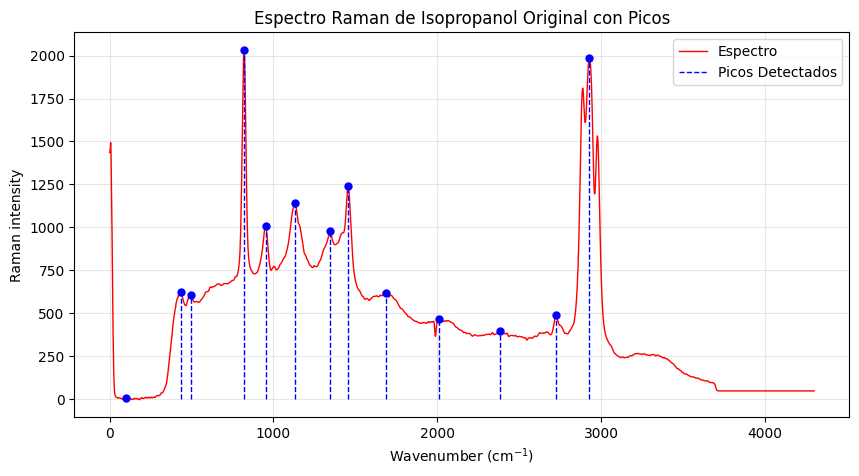

In [28]:
# Graficar el espectro Raman de isopropanol limpio incluyendo los picos con líneas verticales (vlines)

plot_raman_spectrum(
    isopropanol_clean,
    peaks=isopropanol_peaks,
    title="Espectro Raman de Isopropanol Original con Picos",
    x_label="Wavenumber (cm$^{-1}$)"
)

## 2.3. Representación conjunta de los espectros Raman

En esta sección representaremos los espectros Raman de etanol e isopropanol en una misma gráfica, utilizando el corrimiento Raman como eje horizontal.

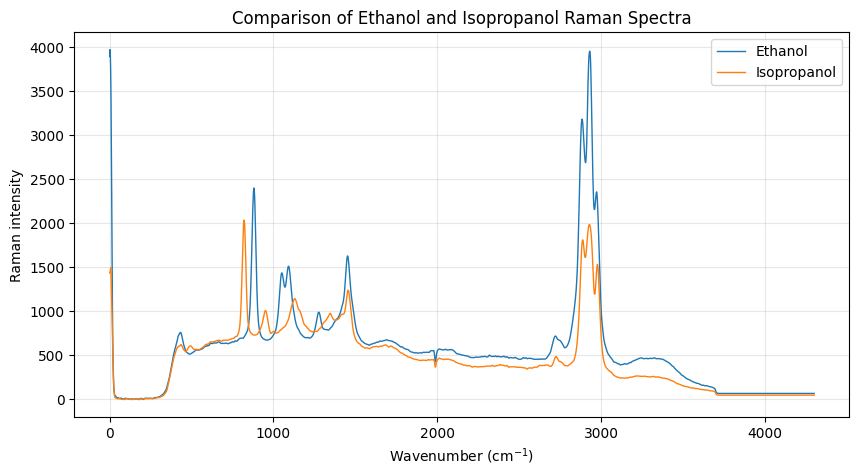

In [29]:
def plot_multiple_raman_spectra(
    spectra,
    labels,
    title,
    x_label
    ):
    """
    Grafica múltiples espectros Raman en la misma figura utilizando la clase Figure.

    Parámetros:
        spectra: lista de DataFrames de espectros Raman limpios
        labels: lista de etiquetas para cada espectro
        title: título del gráfico
        x_label: etiqueta del eje x
    """

    # Crear la figura y los ejes
    fig, ax = plt.subplots(figsize=(10, 5))

    # Graficar cada espectro
    for spectrum, label in zip(spectra, labels):
        ax.plot(
            spectrum.index,
            spectrum["Intensity"],
            linewidth=1,
            label=label
        )

    # Etiquetas de los ejes
    ax.set_xlabel(x_label)
    ax.set_ylabel("Raman intensity")

    # Título del gráfico
    ax.set_title(title)

    # Añadir leyenda
    ax.legend()

    # Añadir cuadrícula
    ax.grid(True, alpha=0.3)

    # Mostrar el gráfico
    plt.show()

plot_multiple_raman_spectra(
    [etanol_clean, isopropanol_clean],
    ["Ethanol", "Isopropanol"],
    title="Comparison of Ethanol and Isopropanol Raman Spectra",
    x_label="Wavenumber (cm$^{-1}$)"
)

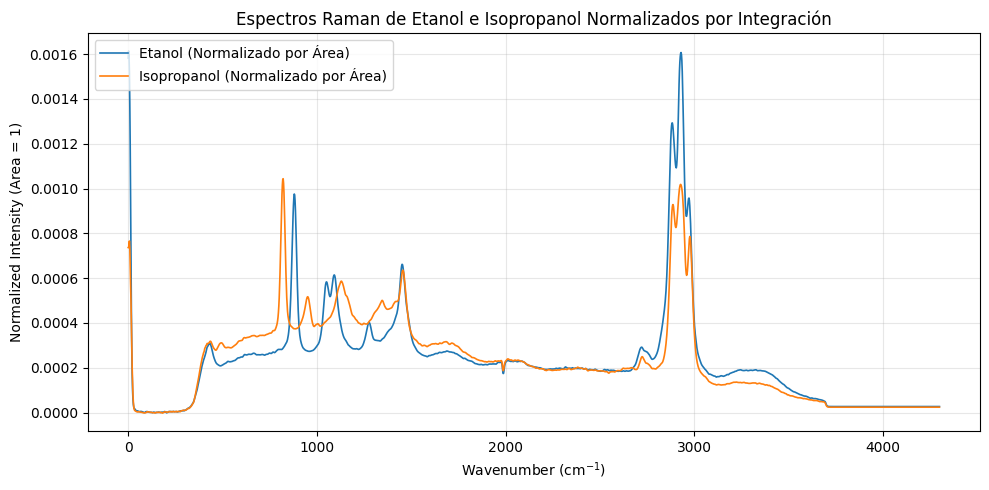

In [30]:
# Calcular el área bajo la curva usando trapezoid para evitar DeprecationWarning
area_etanol = trapezoid(etanol_clean["Intensity"], x=etanol_clean.index)
area_isopropanol = trapezoid(isopropanol_clean["Intensity"], x=isopropanol_clean.index)

# Crear copias de los DataFrames para almacenar los espectros normalizados
etanol_integrado = etanol_clean.copy()
isopropanol_integrado = isopropanol_clean.copy()

# Dividir cada intensidad por su respectiva área (la integral del espectro ahora es igual a 1)
etanol_integrado["Intensity"] = etanol_clean["Intensity"] / area_etanol
isopropanol_integrado["Intensity"] = isopropanol_clean["Intensity"] / area_isopropanol

# Graficar ambos espectros normalizados por integración en una sola figura
plt.figure(figsize=(10, 5))

plt.plot(
    etanol_integrado.index,
    etanol_integrado["Intensity"],
    linewidth=1.2,
    label="Etanol (Normalizado por Área)"
)

plt.plot(
    isopropanol_integrado.index,
    isopropanol_integrado["Intensity"],
    linewidth=1.2,
    label="Isopropanol (Normalizado por Área)"
)

# Configurar las etiquetas de los ejes y el título en español
plt.xlabel("Wavenumber (cm$^{-1}$)")
plt.ylabel("Normalized Intensity (Area = 1)")
plt.title("Espectros Raman de Etanol e Isopropanol Normalizados por Integración")
plt.grid(True, alpha=0.3)
plt.legend(loc="upper left")

plt.tight_layout()
plt.show()

## 2.4. Conversión al número de onda absoluto

En esta sección convertiremos el corrimiento Raman de los espectros de etanol e isopropanol al número de onda absoluto de la luz dispersada, utilizando un láser de 532 nm.

El número de onda del láser incidente se calcula mediante:

$$
\tilde{\nu}_{\mathrm{láser}}=\frac{1}{\lambda_{\mathrm{láser}}}
$$

Expresando la longitud de onda en centímetros:

$$
\tilde{\nu}_{\mathrm{láser}}
=\frac{1}{532\times10^{-7}\ \mathrm{cm}}
\approx 18797\ \mathrm{cm}^{-1}
$$

Para la dispersión Stokes, el número de onda absoluto de la luz dispersada se obtiene mediante:

$$
\boxed{
\tilde{\nu}_{\mathrm{dispersada}}
=\tilde{\nu}_{\mathrm{láser}}-\Delta\tilde{\nu}_{\mathrm{Raman}}
}
$$

Finalmente, representaremos ambos espectros en una misma gráfica utilizando el número de onda absoluto como eje horizontal.

In [31]:
# Calcular el número de onda del láser incidente (532 nm)
laser_wavelength_nm = 532     # Láser de color verde
laser_wavenumber = 1 / (laser_wavelength_nm * 1e-7)

# Construir y renderizar el informe del láser usando f-strings crudas (fr) para evitar SyntaxWarning
informe_laser = fr"""
### Número de Onda del Láser de Excitación

* Longitud de onda del láser ($\lambda_{{láser}}$): {laser_wavelength_nm} nm
* Número de onda absoluto del láser ($\tilde{{\nu}}_{{láser}}$): {laser_wavenumber:,.2f} cm$^{{-1}}$
"""

dMarkdown(informe_laser)


### Número de Onda del Láser de Excitación

* Longitud de onda del láser ($\lambda_{láser}$): 532 nm
* Número de onda absoluto del láser ($\tilde{\nu}_{láser}$): 18,796.99 cm$^{-1}$


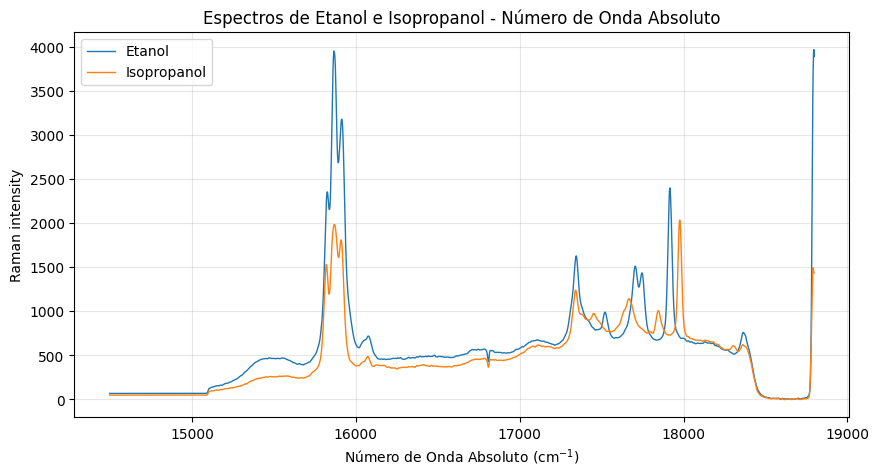

In [32]:
# Convertir el desplazamiento Raman a número de onda absoluto
etanol_absolute = etanol_clean.copy()
isopropanol_absolute = isopropanol_clean.copy()

etanol_absolute.index = laser_wavenumber - etanol_absolute.index
isopropanol_absolute.index = laser_wavenumber - isopropanol_absolute.index

# Ordenar los espectros por número de onda absoluto
etanol_absolute = etanol_absolute.sort_index()
isopropanol_absolute = isopropanol_absolute.sort_index()

# Renombrar el índice del eje X
etanol_absolute.index.name = "Número de Onda Absoluto"
isopropanol_absolute.index.name = "Número de Onda Absoluto"

# Graficar ambos espectros usando el número de onda absoluto en español
plot_multiple_raman_spectra(
    [etanol_absolute, isopropanol_absolute],
    ["Etanol", "Isopropanol"],
    title="Espectros de Etanol e Isopropanol - Número de Onda Absoluto",
    x_label="Número de Onda Absoluto (cm$^{-1}$)"
)

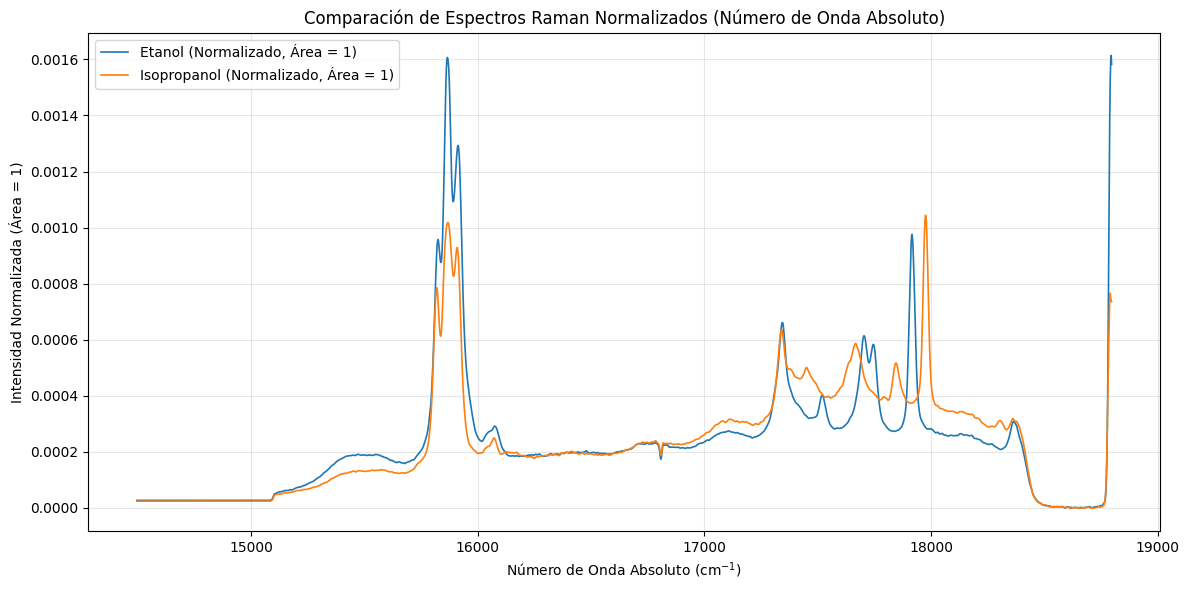

In [33]:
# ============================================================
# Gráfico Comparativo de Espectros Normalizados por Integración
# en función del Número de Onda Absoluto
# ============================================================

# Calcular el área bajo la curva de los espectros en escala absoluta
area_etanol_abs = trapezoid(etanol_absolute["Intensity"], x=etanol_absolute.index)
area_isopropanol_abs = trapezoid(isopropanol_absolute["Intensity"], x=isopropanol_absolute.index)

plt.figure(figsize=(12, 6))

# Graficar el espectro de etanol absoluto normalizado
plt.plot(
    etanol_absolute.index,
    etanol_absolute["Intensity"] / area_etanol_abs,
    label=f"Etanol (Normalizado, Área = 1)",
    linewidth=1.2
)

# Graficar el espectro de isopropanol absoluto normalizado
plt.plot(
    isopropanol_absolute.index,
    isopropanol_absolute["Intensity"] / area_isopropanol_abs,
    label=f"Isopropanol (Normalizado, Área = 1)",
    linewidth=1.2
)

# Configurar ejes y títulos en español con f-strings
plt.xlabel(f"Número de Onda Absoluto (cm$^{{-1}}$)")
plt.ylabel(f"Intensidad Normalizada (Área = 1)")
plt.title(f"Comparación de Espectros Raman Normalizados (Número de Onda Absoluto)")

# Ajustar detalles estéticos
plt.grid(True, alpha=0.3)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

## 2.5. Identificación de bandas Raman y asignación de modos vibracionales

### 2.5.1 Etanol

In [34]:
# Seleccionar la región que contiene las tres bandas de estiramiento C-H
region_ch = etanol_clean.loc[
    (etanol_clean.index >= 2800) &
    (etanol_clean.index <= 3000)
]

# Encontrar máximos locales en la región seleccionada
indices_ch, _ = find_peaks(
    region_ch["Intensity"].to_numpy(),
    prominence=20,
    distance=5
)

# Crear un DataFrame con las posiciones e intensidades de los picos C-H detectados
picos_extra_ch = region_ch.iloc[indices_ch].copy()
picos_extra_ch.index.name = "Posición_del_Pico"
picos_extra_ch = picos_extra_ch.rename(
    columns={"Intensity": "Intensidad_del_Pico"}
)

# Mostrar los máximos detectados de forma estética usando dMarkdown
informe_ch = f"""
### Máximos Locales Detectados en la Región C-H (2800-3000 cm$^{{-1}}$)

{picos_extra_ch.to_markdown()}
"""
dMarkdown(informe_ch)


# Identificar máximos locales en la región de 1000-1150 cm-1 (Región del doblete C-O)
region_co = etanol_clean.loc[1000:1150, "Intensity"]

indices_co, _ = find_peaks(region_co.to_numpy(), prominence=20)

picos_cercanos_co = region_co.iloc[indices_co].to_frame(name="Intensidad_del_Pico")
picos_cercanos_co.index.name = "Posición_del_Pico"

informe_co = f"""
### Máximos Locales Detectados en la Región C-O (1000-1150 cm$^{{-1}}$)

{picos_cercanos_co.to_markdown()}
"""
dMarkdown(informe_co)


### Máximos Locales Detectados en la Región C-H (2800-3000 cm$^{-1}$)

|   Posición_del_Pico |   Intensidad_del_Pico |
|--------------------:|----------------------:|
|             2884.17 |               3181.24 |
|             2930.39 |               3953.72 |
|             2972.4  |               2355.7  |



### Máximos Locales Detectados en la Región C-O (1000-1150 cm$^{-1}$)

|   Posición_del_Pico |   Intensidad_del_Pico |
|--------------------:|----------------------:|
|             1050.32 |               1435.6  |
|             1092.33 |               1511.97 |


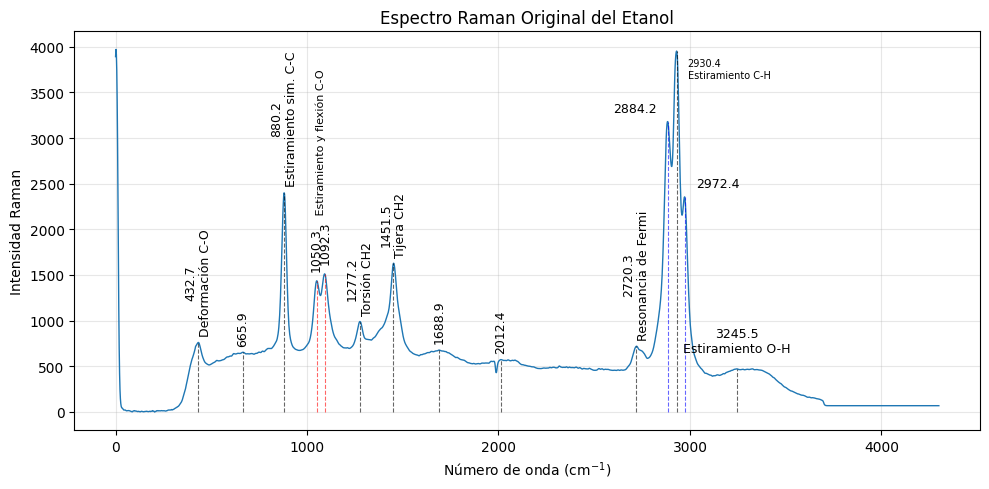

In [35]:
# Asignaciones de bandas Raman basadas en la literatura
assignments = {
    432.73: "Deformación C-O",
    880.17: "Estiramiento sim. C-C",
    1277.19: "Torsión CH2",
    1451.54: "Tijera CH2",
    2720.32: "Resonancia de Fermi",
    2930.39: "Estiramiento C-H",
    3245.48: "Estiramiento O-H",
}

# Dos picos que forman el doblete de estiramiento y flexión C-O
co_doublet_peaks = [1050.317538, 1092.330239]

# Máximos locales adicionales encontrados en la región de estiramiento C-H
additional_peaks = [2884.171959, 2972.398632]

# Picos cuyas etiquetas no se mostrarán
hidden_peaks = [2317, 2371, 2474, 2525]

# Crear la figura
plt.figure(figsize=(10, 5))

# Graficar el espectro limpio de etanol
plt.plot(
    etanol_clean.index,
    etanol_clean["Intensity"],
    linewidth=1
)

# Anotar los picos del CSV original
for position, row in etanol_peaks.iterrows():

    # Ocultar la etiqueta del último pico para evitar superposición con el estiramiento O-H
    if abs(position - 3325.31) <= 3:
        continue

    # Ocultar picos que no contribuyen a la caracterización
    if any(abs(position - peak) <= 3 for peak in hidden_peaks):
        continue

    # El doblete C-O se anotará por separado
    if any(abs(position - peak) <= 3 for peak in co_doublet_peaks):
        continue

    # Encontrar la posición de referencia asignada más cercana
    closest_position = min(
        assignments,
        key=lambda reference: abs(reference - position)
    )

    # Crear la etiqueta
    if abs(closest_position - position) <= 3:
        label = f"{position:.1f}\n{assignments[closest_position]}"
    else:
        label = f"{position:.1f}"

    # Agregar línea vertical para el pico
    plt.vlines(
        x=position,
        ymin=0,
        ymax=row["Peak_Intensity"],
        color="k",
        linestyle="--",
        linewidth=0.8,
        alpha=0.6
    )

    # Pico central C-H: etiqueta horizontal a la derecha
    if abs(position - 2930.39) <= 3:
        plt.annotate(
            label,
            xy=(position, row["Peak_Intensity"]),
            xytext=(8, -5),
            textcoords="offset points",
            ha="left",
            va="top",
            fontsize=7,
            rotation=0
        )

    # Pico O-H: etiqueta horizontal sobre el pico
    elif abs(position - 3245.48) <= 3:
        plt.annotate(
            label,
            xy=(position, row["Peak_Intensity"]),
            xytext=(0, 10),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
            rotation=0
        )

    # Todas las demás etiquetas de picos originales permanecen verticales
    else:
        plt.annotate(
            label,
            xy=(position, row["Peak_Intensity"]),
            xytext=(0, 7),
            textcoords="offset points",
            ha="center",
            fontsize=9,
            rotation=90
        )

# Anotar ambos picos del doblete C-O
doublet_intensities = []

for position in co_doublet_peaks:

    # Encontrar el índice más cercano en el espectro limpio
    nearest_index = (
        etanol_clean.index.to_series() - position
    ).abs().idxmin()

    intensity = etanol_clean.loc[
        nearest_index, "Intensity"
    ]

    doublet_intensities.append(intensity)

    # Agregar línea vertical para el doblete
    plt.vlines(
        x=nearest_index,
        ymin=0,
        ymax=intensity,
        color="r",
        linestyle="--",
        linewidth=0.8,
        alpha=0.6
    )

    # Mostrar la posición experimental del pico verticalmente
    plt.annotate(
        f"{position:.1f}",
        xy=(nearest_index, intensity),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9,
        rotation=90
    )

# Agregar una etiqueta compartida sobre el doblete C-O
doublet_center = sum(co_doublet_peaks) / 2
doublet_max_intensity = max(doublet_intensities)

plt.annotate(
    "       Estiramiento y flexión C-O",
    xy=(doublet_center, doublet_max_intensity),
    xytext=(0, 25),
    textcoords="offset points",
    ha="center",
    va="bottom",
    fontsize=8,
    rotation=90
)

# Agregar los dos máximos de estiramiento C-H adicionales
for position in additional_peaks:

    # Encontrar el índice más cercano en el espectro limpio
    nearest_index = (
        etanol_clean.index.to_series() - position
    ).abs().idxmin()

    intensity = etanol_clean.loc[
        nearest_index, "Intensity"
    ]

    # Agregar línea vertical para el pico adicional
    plt.vlines(
        x=nearest_index,
        ymin=0,
        ymax=intensity,
        color="b",
        linestyle="--",
        linewidth=0.8,
        alpha=0.6
    )

    # Posicionar las etiquetas en lados opuestos
    if position < 2930.39:
        offset = (-8, 5)
        alignment = "right"
    else:
        offset = (8, 5)
        alignment = "left"

    plt.annotate(
        f"{position:.1f}",
        xy=(nearest_index, intensity),
        xytext=offset,
        textcoords="offset points",
        ha=alignment,
        va="bottom",
        fontsize=9,
        rotation=0
    )

# Etiquetas de los ejes
plt.xlabel("Número de onda (cm$^{-1}$)")
plt.ylabel("Intensidad Raman")

# Título del gráfico
plt.title("Espectro Raman Original del Etanol")

# Agregar cuadrícula
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

La identificación de las bandas Raman del etanol se realizó comparando las posiciones de los máximos experimentales con las asignaciones vibracionales reportadas en la literatura. Se consideraron las referencias de Cersoy et al. (2020), PhysicsOpenLab (2022) y ScanCoTec.

### 2.5.2 Asignación de las principales bandas

- **432.73 cm⁻¹:** deformación del enlace C–O (C–O deflection).

- **880.17 cm⁻¹:** estiramiento simétrico del enlace C–C (C–C sym. stretching).

- **1050.32 y 1092.33 cm⁻¹:** doblete asociado conjuntamente al estiramiento y la flexión del enlace C–O (C–O stretch & bend), de acuerdo con la gráfica de ScanCoTec. La fuente no especifica por separado el modo vibracional correspondiente a cada máximo.

- **1277.19 cm⁻¹:** torsión del grupo CH₂ (CH₂ twisting).

- **1451.54 cm⁻¹:** deformación angular del grupo CH₂ (CH₂ scissoring).

- **2720.32 cm⁻¹:** banda asociada a una posible resonancia de Fermi (Fermi resonance), relacionada con la interacción entre estados vibracionales.

- **2884.17, 2930.39 y 2972.40 cm⁻¹:** estiramientos C–H de los grupos CH₃ y CH₂ (CH₃–CH₂ stretching).

- **3245.48 cm⁻¹:** estiramiento del enlace O–H (O–H stretching).

# 2.5.1 Isopropanol

In [36]:
# Identificar máximos locales adicionales en la región de estiramiento C-H
region = isopropanol_clean.loc[2800:3050, "Intensity"]

indices, _ = find_peaks(region.to_numpy(), prominence=20)

additional_peaks = region.iloc[indices].to_frame(name="Intensidad_del_Pico")
additional_peaks.index.name = "Posición_del_Pico"

display(additional_peaks)

# Identificar máximos locales en la región de estiramiento O-H
region = isopropanol_clean.loc[3100:3600, "Intensity"]

indices, _ = find_peaks(region.to_numpy(), prominence=20)

oh_peaks = region.iloc[indices].to_frame(name="Intensidad_del_Pico")
oh_peaks.index.name = "Posición_del_Pico"

display(oh_peaks)

,Intensidad_del_Pico
Posición_del_Pico,
2888.373229,1809.291
2928.285296,1985.334
2976.599902,1531.798


,Intensidad_del_Pico
Posición_del_Pico,
3222.374206,265.8063


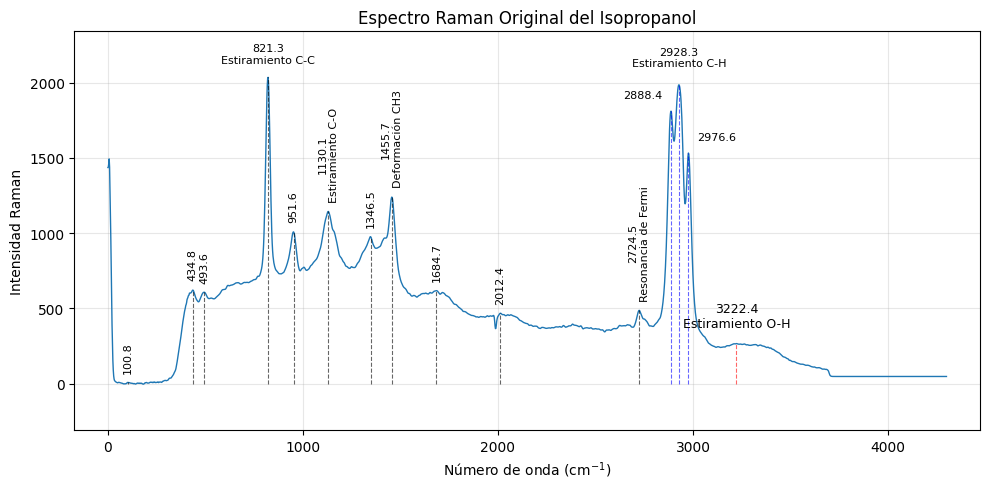

In [37]:
# Asignaciones de bandas Raman del isopropanol basadas en la literatura
assignments = {
    821.35: "Estiramiento C-C",
    1130.14: "Estiramiento C-O",
    1455.74: "Deformación CH3",
    2724.52: "Resonancia de Fermi",
}

# Tres máximos identificados en la región de estiramiento C-H
ch_peaks = [
    2888.373229,
    2928.285296,
    2976.599902
]

# Máximo O-H detectado a partir del espectro experimental
oh_position = float(oh_peaks.index[0])
oh_intensity = float(oh_peaks.iloc[0]["Intensidad_del_Pico"])

# Región cuyas etiquetas de picos se ocultarán
# La curva experimental permanece inalterada
hidden_region = (2300, 2550)

# Crear la figura
plt.figure(figsize=(10, 5))

# Graficar el espectro limpio de isopropanol
plt.plot(
    isopropanol_clean.index,
    isopropanol_clean["Intensity"],
    linewidth=1
)

# Anotar los picos exportados por el espectrómetro
for position, row in isopropanol_peaks.iterrows():

    # Ocultar etiquetas en la región seleccionada
    if hidden_region[0] <= position <= hidden_region[1]:
        continue

    # Evitar duplicar los picos C-H
    if any(abs(position - peak) <= 3 for peak in ch_peaks):
        continue

    # Evitar duplicar la etiqueta O-H
    if abs(position - oh_position) <= 3:
        continue

    # Encontrar la asignación de literatura más cercana
    closest_position = min(
        assignments,
        key=lambda reference: abs(reference - position)
    )

    if abs(closest_position - position) <= 3:
        label = (
            f"{position:.1f}\n"
            f"{assignments[closest_position]}"
        )
    else:
        label = f"{position:.1f}"

    # Agregar línea vertical para el pico del espectrómetro
    plt.vlines(
        x=position,
        ymin=0,
        ymax=row["Peak_Intensity"],
        color="k",
        linestyle="--",
        linewidth=0.8,
        alpha=0.6
    )

    # Mantener el estiramiento C-C en posición horizontal
    if abs(position - 821.35) <= 3:
        plt.annotate(
            label,
            xy=(position, row["Peak_Intensity"]),
            xytext=(0, 9),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=8,
            rotation=0,
            annotation_clip=False
        )
    else:
        plt.annotate(
            label,
            xy=(position, row["Peak_Intensity"]),
            xytext=(0, 7),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=8,
            rotation=90
        )

# Anotar los tres máximos de estiramiento C-H
for position in ch_peaks:

    # Encontrar el punto de datos experimental más cercano
    nearest_index = (
        isopropanol_clean.index.to_series() - position
    ).abs().idxmin()

    intensity = isopropanol_clean.loc[
        nearest_index, "Intensity"
    ]

    # Agregar línea vertical azul para la región C-H adicional
    plt.vlines(
        x=nearest_index,
        ymin=0,
        ymax=intensity,
        color="b",
        linestyle="--",
        linewidth=0.8,
        alpha=0.6
    )

    if position < 2920:
        # Primer pico C-H
        label = f"{position:.1f}"
        offset = (-6, 8)
        alignment = "right"
        vertical_alignment = "bottom"

    elif position < 2950:
        # Pico central C-H: mostrar la asignación horizontalmente
        label = f"{position:.1f}\nEstiramiento C-H"
        offset = (0, 12)
        alignment = "center"
        vertical_alignment = "bottom"

    else:
        # Tercer pico C-H
        label = f"{position:.1f}"
        offset = (6, 8)
        alignment = "left"
        vertical_alignment = "bottom"

    plt.annotate(
        label,
        xy=(nearest_index, intensity),
        xytext=offset,
        textcoords="offset points",
        ha=alignment,
        va=vertical_alignment,
        fontsize=8,
        rotation=0,
        annotation_clip=False
    )

# Agregar línea vertical roja para el máximo de O-H detectado
plt.vlines(
    x=oh_position,
    ymin=0,
    ymax=oh_intensity,
    color="r",
    linestyle="--",
    linewidth=0.8,
    alpha=0.6
)

# Anotar horizontalmente el máximo de O-H
plt.annotate(
    f"{oh_position:.1f}\nEstiramiento O-H",
    xy=(oh_position, oh_intensity),
    xytext=(0, 10),
    textcoords="offset points",
    ha="center",
    va="bottom",
    fontsize=9,
    rotation=0,
    annotation_clip=False
)

plt.xlabel("Número de onda (cm$^{-1}$)")
plt.ylabel("Intensidad Raman")
plt.title("Espectro Raman Original del Isopropanol")
plt.grid(True, alpha=0.3)

# Añadir márgenes para evitar recortar las anotaciones
plt.margins(x=0.04, y=0.15)
plt.tight_layout()
plt.show()

La identificación de las bandas Raman del isopropanol se realizó comparando las posiciones de los máximos experimentales con las asignaciones vibracionales reportadas en la literatura. Se consideraron las referencias de Cersoy et al. (2020), PhysicsOpenLab (2022), Steve's Open Lab y Agilent Technologies (2023).

### Asignación de las principales bandas

- **821.35 cm⁻¹:** vibración del esqueleto molecular C–C–O (C–C–O skeletal vibration), característica del isopropanol y de su estructura ramificada.

- **951.59 cm⁻¹:** estiramiento del enlace C–O (C–O stretching), de acuerdo con la asignación reportada por Agilent para la banda cercana a 954 cm⁻¹.

- **1130.14 cm⁻¹:** banda asignada al estiramiento C–O (C–O stretching) en Steve's Open Lab. La fuente también menciona contribuciones del movimiento de balanceo del grupo CH₃ (CH₃ rocking) y de los modos del esqueleto C–C. Como Agilent sitúa el estiramiento C–O cerca de 954 cm⁻¹, las referencias presentan diferencias en la interpretación de esta región. Por ello, no se concluye que ambas bandas correspondan a dos estiramientos C–O independientes.

- **1455.74 cm⁻¹:** deformación del grupo CH₃ (CH₃ bending), compatible con la banda reportada alrededor de 1454 cm⁻¹.

- **2724.52 cm⁻¹:** banda asociada a una resonancia de Fermi (Fermi resonance) o a una banda de combinación, según la interpretación descrita en Steve's Open Lab.

- **2888.37, 2928.29 y 2976.60 cm⁻¹:** máximos de la región de estiramiento C–H (C–H stretching), asociados a los grupos CH₃ y al grupo CH de la molécula. Se presentan conjuntamente sin asignar cada máximo a un modo vibracional individual.

- **3222.37 cm⁻¹:** estiramiento del enlace O–H (O–H stretching).

El máximo de **1346.51 cm⁻¹** se conserva en los datos experimentales, pero no se le asigna un modo vibracional específico, ya que no se encontró una correspondencia clara en las referencias consultadas.

Otros máximos experimentales, como los de 100.83, 434.83, 493.65, 1684.71, 2012.41 y 2382.12 cm⁻¹, no se asignaron de manera concluyente. Su presencia se conserva en el espectro, sin atribuirles un origen molecular específico.



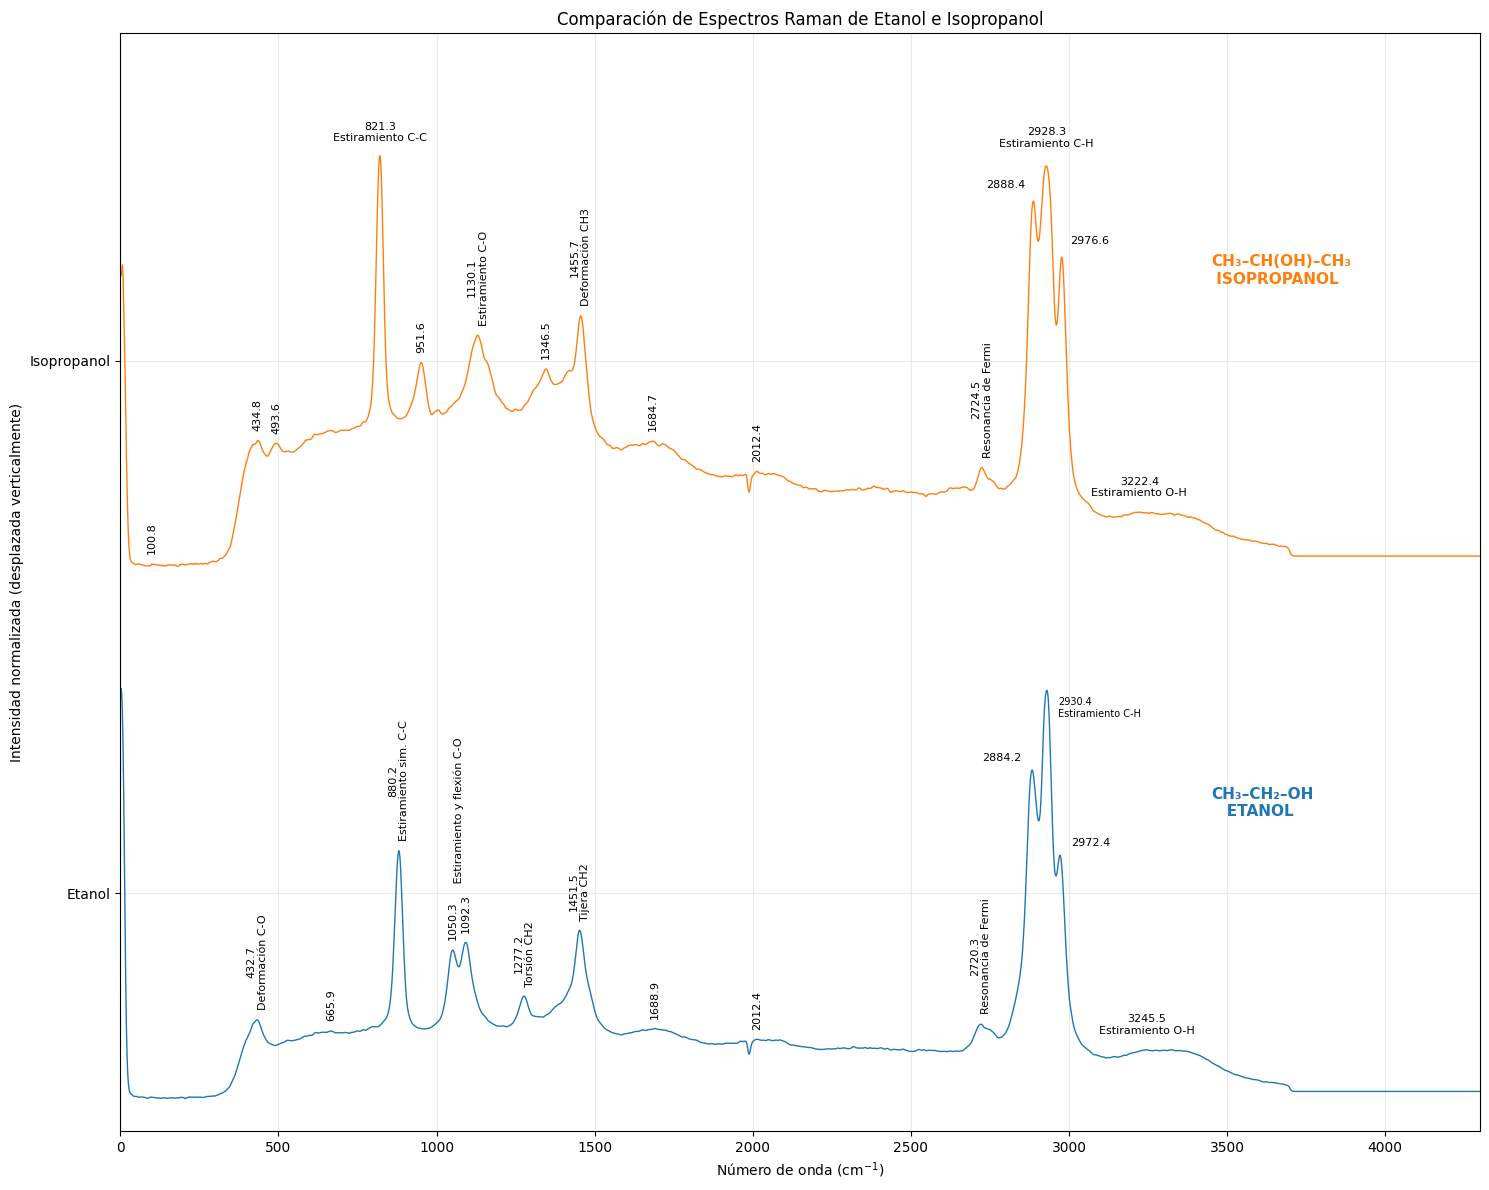

In [38]:
# ============================================================
# 1. Asignaciones de bandas Raman basadas en la literatura
# ============================================================

asignaciones_etanol = {
    432.73: "Deformación C-O",
    880.17: "Estiramiento sim. C-C",
    1277.19: "Torsión CH2",
    1451.54: "Tijera CH2",
    2720.32: "Resonancia de Fermi",
    2930.39: "Estiramiento C-H",
    3245.48: "Estiramiento O-H",
}

asignaciones_isopropanol = {
    821.35: "Estiramiento C-C",
    1130.14: "Estiramiento C-O",
    1455.74: "Deformación CH3",
    2724.52: "Resonancia de Fermi",
}

# Etanol: dos picos que forman el doblete C-O
picos_doblete_co = [
    1050.317538,
    1092.330239
    ]

# Etanol: máximos locales adicionales en la región C-H
picos_ch_etanol = [
    2884.171959,
    2972.398632
    ]

# Isopropanol: tres máximos en la región C-H
picos_ch_isopropanol = [
    2888.373229,
    2928.285296,
    2976.599902
    ]

# Picos cuyas etiquetas se ocultarán en el espectro de etanol
picos_ocultos_etanol = [2317, 2371, 2474, 2525]

# Isopropanol: región donde se ocultan las etiquetas, pero no la curva
region_oculta_isopropanol = (2300, 2550)

# Máximo de O-H detectado para el isopropanol
oh_position = float(oh_peaks.index[0])


# ============================================================
# 2. Normalizar cada espectro de manera independiente
# ============================================================

etanol_norm = (
    etanol_clean["Intensity"].astype(float)
    / etanol_clean["Intensity"].max()
)

isopropanol_norm = (
    isopropanol_clean["Intensity"].astype(float)
    / isopropanol_clean["Intensity"].max()
)

# Desplazamientos verticales para separar ambos espectros normalizados
etanol_offset = 0.0
isopropanol_offset = 1.30


# ============================================================
# 3. Función auxiliar para localizar un punto en el espectro normalizado
# ============================================================

def punto_en_espectro(espectro, intensidad_normalizada,
                      posicion, desplazamiento_vertical):
    """
    Retorna la coordenada X experimental más cercana y su
    intensidad normalizada, incluyendo el desplazamiento vertical.
    """
    valores_x = np.asarray(espectro.index, dtype=float)
    indice_cercano = int(
        np.abs(valores_x - float(posicion)).argmin()
    )
    valor_x = float(valores_x[indice_cercano])
    valor_y = (
        float(intensidad_normalizada.iloc[indice_cercano])
        + desplazamiento_vertical
    )
    return valor_x, valor_y


# ============================================================
# 4. Crear el gráfico comparativo
# ============================================================

fig, ax = plt.subplots(figsize=(15, 12))
# Graficar etanol en la posición inferior
linea_etanol, = ax.plot(
    etanol_clean.index,
    etanol_norm + etanol_offset,
    linewidth=1,
    label="Etanol"
)
# Graficar isopropanol en la posición superior
linea_isopropanol, = ax.plot(
    isopropanol_clean.index,
    isopropanol_norm + isopropanol_offset,
    linewidth=1,
    label="Isopropanol"
)

# ============================================================
# 5. Anotar los picos de etanol a partir del CSV original
# ============================================================

for position, row in etanol_peaks.iterrows():
    position = float(position)
    # Ocultar la etiqueta de 3325 cm-1 para evitar superposición con el estiramiento O-H
    if abs(position - 3325.31) <= 3:
        continue
    # Ocultar etiquetas seleccionadas; se conserva la curva experimental
    if any(
        abs(position - peak) <= 3
        for peak in picos_ocultos_etanol
    ):
        continue
    # El doblete C-O se anotará por separado abajo
    if any(
        abs(position - peak) <= 3
        for peak in picos_doblete_co
    ):
        continue
    # Encontrar la posición de referencia asignada más cercana
    posicion_cercana = min(
        asignaciones_etanol,
        key=lambda referencia: abs(referencia - position)
    )
    if abs(posicion_cercana - position) <= 3:
        label = (
            f"{position:.1f}\n"
            f"{asignaciones_etanol[posicion_cercana]}"
        )
    else:
        label = f"{position:.1f}"
    x_peak, y_peak = punto_en_espectro(
        etanol_clean, etanol_norm,
        position, etanol_offset
    )
    # Pico central C-H: etiqueta horizontal a la derecha
    if abs(position - 2930.39) <= 3:
        ax.annotate(
            label,
            xy=(x_peak, y_peak),
            xytext=(8, -5),
            textcoords="offset points",
            ha="left",
            va="top",
            fontsize=7,
            rotation=0
        )
    # Pico O-H: etiqueta horizontal arriba de la señal
    elif abs(position - 3245.48) <= 3:
        ax.annotate(
            label,
            xy=(x_peak, y_peak),
            xytext=(0, 10),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=8,
            rotation=0
        )
    # Todas las demás etiquetas de picos originales permanecen verticales
    else:
        ax.annotate(
            label,
            xy=(x_peak, y_peak),
            xytext=(0, 7),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=8,
            rotation=90
        )

# ============================================================
# 6. Anotar los dos picos del doblete C-O de etanol
# ============================================================

puntos_doblete = []
for position in picos_doblete_co:
    x_peak, y_peak = punto_en_espectro(
        etanol_clean, etanol_norm,
        position, etanol_offset
    )
    puntos_doblete.append((x_peak, y_peak))
    ax.annotate(
        f"{position:.1f}",
        xy=(x_peak, y_peak),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=8,
        rotation=90
    )

centro_doblete = sum(picos_doblete_co) / 2
max_y_doblete = max(y for x, y in puntos_doblete)

ax.annotate(
    "       Estiramiento y flexión C-O",
    xy=(centro_doblete, max_y_doblete),
    xytext=(0, 25),
    textcoords="offset points",
    ha="center",
    va="bottom",
    fontsize=8,
    rotation=90
)

# ============================================================
# 7. Anotar los dos máximos C-H adicionales de etanol
# ============================================================

for position in picos_ch_etanol:
    x_peak, y_peak = punto_en_espectro(
        etanol_clean, etanol_norm,
        position, etanol_offset
    )
    if position < 2930.39:
        desplazamiento_texto = (-8, 5)
        alignment = "right"
    else:
        desplazamiento_texto = (8, 5)
        alignment = "left"
    ax.annotate(
        f"{position:.1f}",
        xy=(x_peak, y_peak),
        xytext=desplazamiento_texto,
        textcoords="offset points",
        ha=alignment,
        va="bottom",
        fontsize=8,
        rotation=0
    )

# ============================================================
# 8. Anotar los picos de isopropanol a partir del CSV original
# ============================================================

for position, row in isopropanol_peaks.iterrows():
    position = float(position)
    # Ocultar etiquetas en la región seleccionada, conservando la curva
    if (
        region_oculta_isopropanol[0]
        <= position
        <= region_oculta_isopropanol[1]
    ):
        continue
    # Evitar duplicar las etiquetas de los tres picos C-H
    if any(
        abs(position - peak) <= 3
        for peak in picos_ch_isopropanol
    ):
        continue
    # Evitar duplicar la etiqueta del O-H
    if abs(position - oh_position) <= 3:
        continue
    # Encontrar la posición de referencia asignada más cercana
    posicion_cercana = min(
        asignaciones_isopropanol,
        key=lambda referencia: abs(referencia - position)
    )
    if abs(posicion_cercana - position) <= 3:
        label = (
            f"{position:.1f}\n"
            f"{asignaciones_isopropanol[posicion_cercana]}"
        )
    else:
        label = f"{position:.1f}"
    x_peak, y_peak = punto_en_espectro(
        isopropanol_clean, isopropanol_norm,
        position, isopropanol_offset
    )
    # Mantener el estiramiento C-C de forma horizontal
    if abs(position - 821.35) <= 3:
        ax.annotate(
            label,
            xy=(x_peak, y_peak),
            xytext=(0, 9),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=8,
            rotation=0,
            annotation_clip=False
        )
    else:
        ax.annotate(
            label,
            xy=(x_peak, y_peak),
            xytext=(0, 7),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=8,
            rotation=90,
            annotation_clip=False
        )

# ============================================================
# 9. Anotar los tres máximos C-H de isopropanol
# ============================================================

for position in picos_ch_isopropanol:

    x_peak, y_peak = punto_en_espectro(
        isopropanol_clean, isopropanol_norm,
        position, isopropanol_offset
    )
    if position < 2920:
        label = f"{position:.1f}"
        desplazamiento_texto = (-6, 8)
        alignment = "right"
        vertical_alignment = "bottom"
    elif position < 2950:
        label = f"{position:.1f}\nEstiramiento C-H"
        desplazamiento_texto = (0, 12)
        alignment = "center"
        vertical_alignment = "bottom"
    else:
        label = f"{position:.1f}"
        desplazamiento_texto = (6, 8)
        alignment = "left"
        vertical_alignment = "bottom"
    ax.annotate(
        label,
        xy=(x_peak, y_peak),
        xytext=desplazamiento_texto,
        textcoords="offset points",
        ha=alignment,
        va=vertical_alignment,
        fontsize=8,
        rotation=0,
        annotation_clip=False
    )

# ============================================================
# 10. Anotar el máximo O-H detectado de isopropanol
# ============================================================

x_oh, y_oh = punto_en_espectro(
    isopropanol_clean, isopropanol_norm,
    oh_position, isopropanol_offset
)
ax.annotate(
    f"{oh_position:.1f}\nEstiramiento O-H",
    xy=(x_oh, y_oh),
    xytext=(0, 10),
    textcoords="offset points",
    ha="center",
    va="bottom",
    fontsize=8,
    rotation=0,
    annotation_clip=False
)

# ============================================================
# 11. Agregar la fórmula estructural condensada de cada compuesto
# ============================================================

formula_x = 3450
# Etanol: CH3-CH2-OH
ax.text(
    formula_x,
    etanol_offset + 0.72,
    "CH₃–CH₂–OH\n   ETANOL",
    color=linea_etanol.get_color(),
    fontsize=11,
    fontweight="bold",
    ha="left",
    va="center"
)

# Isopropanol: CH3-CH(OH)-CH3
ax.text(
    formula_x,
    isopropanol_offset + 0.72,
    "CH₃–CH(OH)–CH₃\n ISOPROPANOL",
    color=linea_isopropanol.get_color(),
    fontsize=11,
    fontweight="bold",
    ha="left",
    va="center"
)

# ============================================================
# 12. Formatear los ejes
# ============================================================

ax.set_xlabel("Número de onda (cm$^{-1}$)")
ax.set_ylabel("Intensidad normalizada (desplazada verticalmente)")
ax.set_title("Comparación de Espectros Raman de Etanol e Isopropanol")
# Etiquetar cada eje vertical de acuerdo al compuesto
ax.set_yticks([
    etanol_offset + 0.5,
    isopropanol_offset + 0.5
])
ax.set_yticklabels(["Etanol", "Isopropanol"])

# Conservar el eje común de número de onda
x_max = max(
    float(etanol_clean.index.max()),
    float(isopropanol_clean.index.max())
)
ax.set_xlim(0, x_max)

# Dar margen para evitar el recorte de señales y anotaciones
ax.set_ylim(-0.08, isopropanol_offset + 1.30)
ax.grid(True, alpha=0.25)
ax.margins(x=0.02)
plt.tight_layout()
plt.show()

## 2.6. Caracterización computacional de los espectros Raman utilizando librerías de Phython

En esta etapa se utilizarán bibliotecas especializadas de Python para analizar los espectros Raman del etanol y del isopropanol a partir de los datos experimentales limpios.

Se emplearán herramientas de análisis espectral para obtener parámetros cuantitativos de las bandas, estudiar sus perfiles y evaluar métodos de ajuste que permitan describir matemáticamente las señales experimentales. También se explorarán procedimientos de análisis comparativo para identificar semejanzas y diferencias entre ambos espectros.

Se utilizarán bibliotecas como RamanSPy y Rampy, junto con las herramientas numéricas que sean necesarias. Los resultados computacionales complementarán la caracterización realizada anteriormente y servirán como base para la interpretación espectroscópica de ambos compuestos.

## 2.6.1 RamanSPy

Vamos a comenzar con **RamanSPy**, una biblioteca especializada en análisis de espectros Raman. Su clase Spectrum permite cargar directamente el eje espectral y las intensidades, y su método peaks() detecta máximos y proporciona propiedades como prominencia y anchura.

Este primer código utiliza únicamente etanol_clean e isopropanol_clean. No usa los picos registrados por el software del espectrómetro ni las asignaciones bibliográficas.
Celda de código: detección y caracterización automática de máximos
Si RamanSPy todavía no está instalado en tu entorno de Jupyter, ejecuta primero `%pip install ramanspy` en una celda aparte.

Primero, detectamos los picos

In [39]:
# Espectros Raman a analizar
spectra = {
    "Ethanol": etanol_clean,
    "Isopropanol": isopropanol_clean
}

def characterize_raman_spectrum(data, prominence=20, distance=4):
    """
    Detecta los máximos espectrales Raman utilizando la clase Spectrum de RamanSPy.

    Parámetros
    ----------
    data : pandas.DataFrame
        Espectro limpio con el número de onda como índice y una columna de intensidad.
    prominence : float
        Prominencia mínima del pico en unidades de intensidad.
    distance : int
        Distancia mínima entre los picos detectados, en puntos de datos.

    Retorna
    ------
    pandas.DataFrame
        Posiciones de los picos detectados, intensidades, intensidades relativas,
        prominencias y anchuras a la mitad de la prominencia.
    """

    # Extraer el eje experimental de número de onda y la intensidad
    x = data.index.to_numpy(dtype=float)
    y = data["Intensity"].to_numpy(dtype=float)

    # Crear el objeto de espectro de RamanSPy
    spectrum = rp.Spectrum(
        spectral_data=y,
        spectral_axis=x
    )

    # Detectar picos y calcular sus propiedades
    peak_indices, properties = spectrum.peaks(
        prominence=prominence,
        distance=distance,
        width=(None, None),
        rel_height=0.5
    )

    # Recuperar el eje y las intensidades en su orden almacenado
    x_axis = spectrum.spectral_axis
    intensity = spectrum.spectral_data

    # Convertir los índices fraccionarios de la anchura del pico a cm-1
    sample_indices = np.arange(len(x_axis))

    left_positions = np.interp(
        properties["left_ips"],
        sample_indices,
        x_axis
    )

    right_positions = np.interp(
        properties["right_ips"],
        sample_indices,
        x_axis
    )

    widths_cm1 = right_positions - left_positions

    # Calcular la intensidad relativa como un porcentaje del máximo
    max_intensity = np.max(intensity)

    if max_intensity > 0:
        relative_intensity = (
            intensity[peak_indices] / max_intensity * 100
        )
    else:
        relative_intensity = np.zeros(len(peak_indices))

    # Construir la tabla de resultados
    results = pd.DataFrame({
        "Peak_Position_cm-1": x_axis[peak_indices],
        "Intensity": intensity[peak_indices],
        "Relative_Intensity_%": relative_intensity,
        "Prominence": properties["prominences"],
        "Width_at_half_prominence_cm-1": widths_cm1
    })

    return results.sort_values(
        "Peak_Position_cm-1"
    ).reset_index(drop=True)


# Analizar ambos espectros Raman limpios de manera independiente usando los parámetros por defecto
raman_results = {}

for compound, spectrum_data in spectra.items():
    dMarkdown(f"### {compound}: picos detectados automáticamente con parámetros por defecto")
    # Llamada utilizando los parámetros por defecto (prominence=20, distance=4)
    results = characterize_raman_spectrum(spectrum_data)
    raman_results[compound] = results
    display(results.round(3).sample(5))

### Ethanol: picos detectados automáticamente con parámetros por defecto

,Peak_Position_cm-1,Intensity,Relative_Intensity_%,Prominence,Width_at_half_prominence_cm-1
16,3245.481,470.377,11.844,80.304,209.425
5,1092.330,1511.969,38.071,817.972,82.276
14,2930.386,3953.719,99.554,3886.852,118.896
12,2720.322,718.260,18.086,132.503,49.593
2,665.901,652.464,16.429,21.464,20.437


### Isopropanol: picos detectados automáticamente con parámetros por defecto

,Peak_Position_cm-1,Intensity,Relative_Intensity_%,Prominence,Width_at_half_prominence_cm-1
13,2888.373,1809.291,88.924,199.049,14.165
7,1346.507,976.172,47.978,77.117,23.321
14,2928.285,1985.334,97.577,1641.617,120.090
2,493.649,606.953,29.831,43.671,25.604
4,951.588,1008.107,49.547,258.636,33.291



### Comparación con los espectros Raman de referencia

Para complementar la caracterización experimental, se utilizaron los espectros Raman de referencia del etanol y del isopropanol disponibles en la base de datos SDBS (*Spectral Database for Organic Compounds*), mantenida por el National Institute of Advanced Industrial Science and Technology (AIST) de Japón.

La base de datos proporciona las posiciones de las bandas y sus intensidades relativas, pero no asigna directamente cada máximo a un modo vibracional. Por ello, las coincidencias espectrales se contrastarán con las asignaciones descritas en la literatura.

#### Etanol

| Número de onda (cm⁻¹) | Intensidad relativa |
|---:|---:|
| 2973 | 46 |
| 2927 | 96 |
| 2876 | 57 |
| 1455 | 22 |
| 1097 | 16 |
| 1063 | 16 |
| 884 | 55 |

**Fuente:** National Institute of Advanced Industrial Science and Technology (AIST), *Spectral Database for Organic Compounds (SDBS)*, espectro Raman del etanol. [Consultar registro](https://sdbs.db.aist.go.jp/CompoundLanding.aspx?sdbsno=1300).

#### Isopropanol

| Número de onda (cm⁻¹) | Intensidad relativa |
|---:|---:|
| 2972 | 41 |
| 2938 | 44 |
| 2919 | 46 |
| 2881 | 45 |
| 1464 | 18 |
| 1132 | 10 |
| 955 | 13 |
| 820 | 95 |

**Fuente:** National Institute of Advanced Industrial Science and Technology (AIST), *Spectral Database for Organic Compounds (SDBS)*, espectro Raman del isopropanol. [Consultar registro](https://sdbs.db.aist.go.jp/CompoundLanding.aspx?sdbsno=2149).

### Comparación automática de los máximos

Se comparan los máximos detectados mediante RamanSPy en los espectros limpios del etanol y del isopropanol con las posiciones de las bandas de referencia obtenidas de SDBS. Para cada banda de referencia, el código identifica el máximo experimental más cercano y calcula la diferencia entre ambas posiciones.

Se utiliza inicialmente una tolerancia de ±15 cm⁻¹ para establecer coincidencias espectrales. Este criterio podrá ajustarse según los resultados. La comparación se realiza por separado para cada compuesto y no utiliza las tablas de picos proporcionadas por el software original del espectrómetro.

Las coincidencias de posición sirven como criterio inicial de correspondencia espectral; la asignación de los modos vibracionales se establece posteriormente mediante la información bibliográfica.

In [40]:
# Datos de referencia Raman de SDBS para ambos compuestos
sdbs_references = {
    "Ethanol": pd.DataFrame({
        "SDBS_Position_cm-1": [2973, 2927, 2876, 1455, 1097, 1063, 884],
        "SDBS_Relative_Intensity": [46, 96, 57, 22, 16, 16, 55]
    }),

    "Isopropanol": pd.DataFrame({
        "SDBS_Position_cm-1": [2972, 2938, 2919, 2881, 1464, 1132, 955, 820],
        "SDBS_Relative_Intensity": [41, 44, 46, 45, 18, 10, 13, 95]
    })
}

# Diferencia máxima permitida entre los picos de referencia y los experimentales
tolerance = 15


def compare_raman_reference(reference, detected_peaks, tolerance=15):
    """
    Compara las bandas de referencia SDBS con los picos detectados por RamanSPy.

    Se reporta el máximo experimental más cercano para cada banda de referencia.
    Si varias bandas de referencia coinciden con el mismo máximo experimental,
    el resultado se marca como ambiguo.
    """

    experimental_positions = detected_peaks[
        "Peak_Position_cm-1"
    ].to_numpy(dtype=float)

    experimental_intensities = detected_peaks[
        "Intensity"
    ].to_numpy(dtype=float)

    experimental_prominences = detected_peaks[
        "Prominence"
    ].to_numpy(dtype=float)

    comparison_rows = []

    # Encontrar el máximo de RamanSPy más cercano para cada banda de referencia
    for _, ref_row in reference.iterrows():

        reference_position = float(
            ref_row["SDBS_Position_cm-1"]
        )

        differences = np.abs(
            experimental_positions - reference_position
        )

        nearest_index = int(np.argmin(differences))
        experimental_position = experimental_positions[nearest_index]

        delta = experimental_position - reference_position
        distance = abs(delta)

        if distance <= tolerance:
            status = "Coincidence within tolerance"
        else:
            status = "No coincidence within tolerance"

        comparison_rows.append({
            "SDBS position (cm-1)": reference_position,
            "SDBS relative intensity": ref_row[
                "SDBS_Relative_Intensity"
            ],
            "Experimental position (cm-1)": experimental_position,
            "Experimental intensity": experimental_intensities[
                nearest_index
            ],
            "Prominence": experimental_prominences[nearest_index],
            "Difference (cm-1)": delta,
            "Result": status,
            "_experimental_index": nearest_index
        })

    results = pd.DataFrame(comparison_rows)

    # Detectar bandas de referencia que apuntan al mismo máximo experimental
    valid_matches = results[
        results["Result"] == "Coincidence within tolerance"
    ]

    match_counts = valid_matches["_experimental_index"].value_counts()

    for idx, row in results.iterrows():

        peak_index = row["_experimental_index"]

        if (
            row["Result"] == "Coincidence within tolerance"
            and match_counts.get(peak_index, 0) > 1
        ):
            results.at[idx, "Result"] = (
                "Ambiguous: shared experimental maximum"
            )

    # Eliminar la columna interna auxiliar
    results = results.drop(columns="_experimental_index")

    return results


# Comparar ambos compuestos utilizando los resultados calculados previamente por RamanSPy
comparaciones_sdbs = {}

for compound, reference in sdbs_references.items():

    detected_peaks = raman_results[compound]

    comparison = compare_raman_reference(
        reference=reference,
        detected_peaks=detected_peaks,
        tolerance=tolerance
    )

    comparaciones_sdbs[compound] = comparison

    dMarkdown(f"### {compound}: comparison with SDBS")
    display(
        comparison.round({
            "Experimental position (cm-1)": 2,
            "Experimental intensity": 3,
            "Prominence": 3,
            "Difference (cm-1)": 2
        })
    )


### Ethanol: comparison with SDBS

,SDBS position (cm-1),SDBS relative intensity,Experimental position (cm-1),Experimental intensity,Prominence,Difference (cm-1),Result
0,2973.0,46,2972.40,2355.705,199.758,-0.60,Coincidence within tolerance
1,2927.0,96,2930.39,3953.719,3886.852,3.39,Coincidence within tolerance
2,2876.0,57,2884.17,3181.238,493.198,8.17,Coincidence within tolerance
3,1455.0,22,1451.54,1628.243,955.566,-3.46,Coincidence within tolerance
4,1097.0,16,1092.33,1511.969,817.972,-4.67,Coincidence within tolerance
5,1063.0,16,1050.32,1435.597,160.936,-12.68,Coincidence within tolerance
6,884.0,55,880.17,2400.255,1970.244,-3.83,Coincidence within tolerance


### Isopropanol: comparison with SDBS

,SDBS position (cm-1),SDBS relative intensity,Experimental position (cm-1),Experimental intensity,Prominence,Difference (cm-1),Result
0,2972.0,41,2976.60,1531.798,337.459,4.60,Coincidence within tolerance
1,2938.0,44,2928.29,1985.334,1641.617,-9.71,Ambiguous: shared experimental maximum
2,2919.0,46,2928.29,1985.334,1641.617,9.29,Ambiguous: shared experimental maximum
3,2881.0,45,2888.37,1809.291,199.049,7.37,Coincidence within tolerance
4,1464.0,18,1455.74,1239.463,510.684,-8.26,Coincidence within tolerance
5,1132.0,10,1130.14,1143.606,377.976,-1.86,Coincidence within tolerance
6,955.0,13,951.59,1008.107,258.636,-3.41,Coincidence within tolerance
7,820.0,95,821.35,2034.638,1987.305,1.35,Coincidence within tolerance


#### Interpretación de las principales coincidencias para el Etanol

La comparación de la tabla anterior permite identificar coincidencias entre los máximos del espectro experimental y las bandas del espectro de referencia. La asignación de los modos vibracionales se establece adicionalmente mediante la información bibliográfica consultada anteriormente.

Las posiciones experimentales presentan pequeñas diferencias respecto a las bandas de referencia. Estas variaciones pueden depender de las condiciones de medición, la resolución espectral y el procesamiento de las señales.

- **880.17 cm⁻¹:** estiramiento simétrico del enlace C–C (C–C sym. stretching), de acuerdo con las asignaciones descritas en la literatura.

- **1050.32 y 1092.33 cm⁻¹:** doblete asociado conjuntamente al estiramiento y la flexión del enlace C–O (C–O stretch & bend), siguiendo la interpretación de la gráfica de ScanCoTec. La fuente no permite asignar inequívocamente cada movimiento a uno de los dos máximos por separado.

- **1451.54 cm⁻¹:** banda de la región de deformación angular del grupo CH₂ (CH₂ scissoring), compatible con las asignaciones vibracionales reportadas para el etanol.

- **2884.17, 2930.39 y 2972.40 cm⁻¹:** estiramientos C–H de los grupos CH₃ y CH₂ (CH₃–CH₂ stretching).

#### Interpretación de las principales coincidencias para el isopropanol

La comparación de la tabla anterior permite identificar coincidencias entre los máximos del espectro experimental y las bandas del espectro de referencia SDBS. La asignación de los modos vibracionales se establece adicionalmente mediante la información bibliográfica consultada.

Las posiciones experimentales presentan pequeñas diferencias respecto a las bandas de referencia. Estas variaciones pueden depender de las condiciones de medición, la resolución espectral y el procesamiento de las señales.

- **821.35 cm⁻¹:** estiramiento del enlace C–C (C–C stretching). Esta banda constituye una característica distintiva del isopropanol y aparece desplazada respecto a la banda cercana a 880 cm⁻¹ del etanol.

- **951.59 cm⁻¹:** máximo experimental coincidente con la banda de referencia próxima a 955 cm⁻¹. Las fuentes consultadas no permiten establecer con suficiente precisión un modo vibracional específico para esta banda.

- **1130.14 cm⁻¹:** estiramiento del enlace C–O (C–O stretching), con posibles contribuciones de otros movimientos acoplados de la molécula.

- **1455.74 cm⁻¹:** banda experimental coincidente con la referencia de 1464 cm⁻¹, situada en la región de deformación de los grupos CH. Se conserva esta interpretación general sin atribuir un modo vibracional más específico.

- **2888.37, 2928.29 y 2976.60 cm⁻¹:** máximos de la región de estiramiento C–H (C–H stretching), asociados a los grupos CH₃ y al grupo CH central del isopropanol. Cersoy et al. (2020) describe contribuciones próximas a 2920 y 2940 cm⁻¹, características que permiten diferenciar este espectro del etanol.

Las bandas de **1346.51 cm⁻¹** y otros máximos experimentales que no presentan correspondencia suficientemente clara con las referencias consultadas se conservan en el espectro, pero no reciben una asignación vibracional específica.

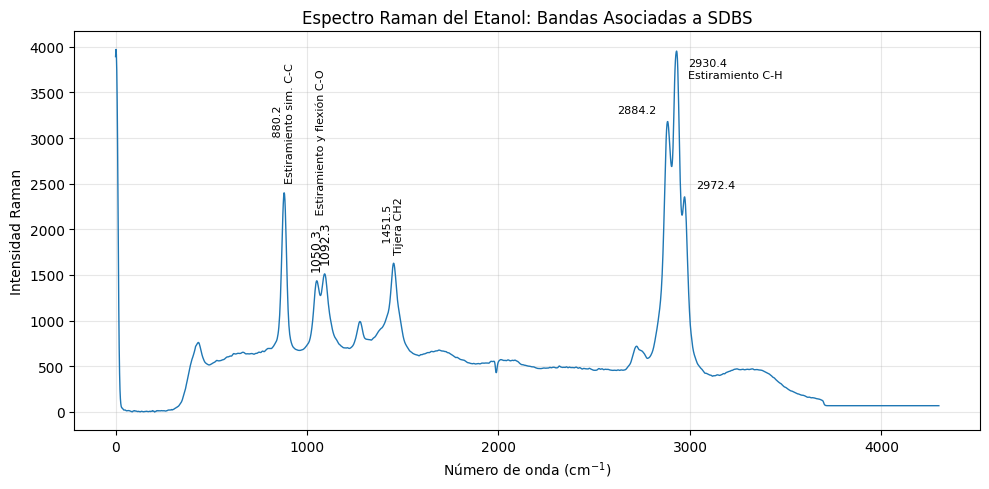

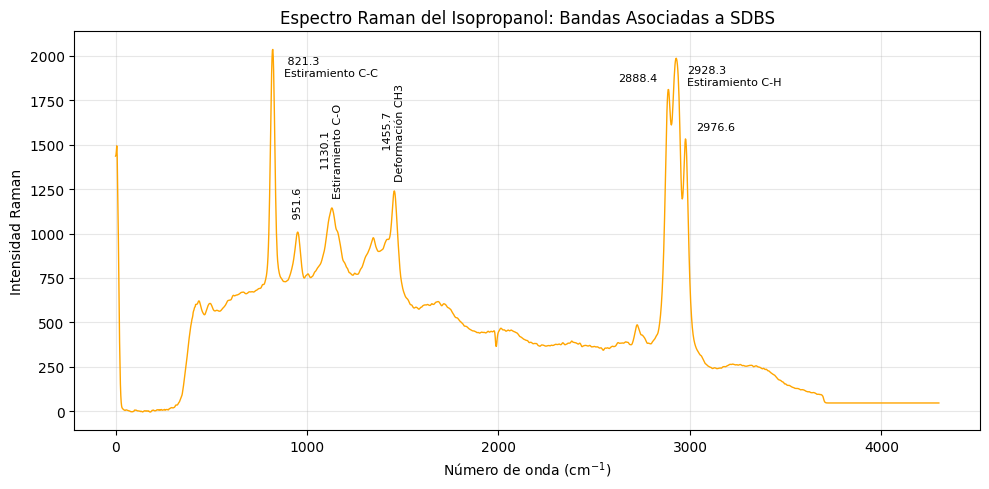

In [41]:
# ============================================================
# 1. Configuración de gráficos y asignaciones por compuesto
# ============================================================

config_graficos = {
    "Ethanol": {
        "spectrum": etanol_clean,
        "comparison": comparaciones_sdbs["Ethanol"],
        "title": "Espectro Raman del Etanol: Bandas Asociadas a SDBS",
        "assignments": {
            880.17: "Estiramiento sim. C-C",
            1451.54: "Tijera CH2",
        },
        "doublet_range": (1000, 1150),
        "doublet_label": "Estiramiento y flexión C-O",
        "horizontal_assignments": [],
    },

    "Isopropanol": {
        "spectrum": isopropanol_clean,
        "comparison": comparaciones_sdbs["Isopropanol"],
        "title": "Espectro Raman del Isopropanol: Bandas Asociadas a SDBS",
        "color": "orange",
        "assignments": {
            821.35: "Estiramiento C-C",
            1130.14: "Estiramiento C-O",
            1455.74: "Deformación CH3",
        },
        "doublet_range": None,
        "doublet_label": None,
        "horizontal_assignments": [821.35],
    }
}


def posiciones_unicas(positions, tolerance=3):
    """Elimina coincidencias duplicadas que apuntan al mismo pico experimental."""
    result = []

    for position in sorted(positions):
        if not any(
            abs(position - existing) <= tolerance
            for existing in result
        ):
            result.append(float(position))

    return result


def graficar_coincidencias_referencia(settings):
    """
    Grafica un espectro Raman limpio y anota los máximos experimentales
    que coinciden con su espectro de referencia SDBS.
    """

    spectrum = settings["spectrum"]
    comparison = settings["comparison"]
    assignments = settings["assignments"]

    # Conservar coincidencias dentro de la tolerancia, incluyendo máximos compartidos
    aceptados = comparison["Result"].isin([
        "Coincidence within tolerance",
        "Ambiguous: shared experimental maximum"
    ])

    matched_positions = posiciones_unicas(
        comparison.loc[
            aceptados, "Experimental position (cm-1)"
        ].dropna().to_list()
    )

    # Seleccionar automáticamente los picos coincidentes en la región de estiramiento C-H
    ch_peaks = [
        position for position in matched_positions
        if 2800 <= position <= 3050
    ]

    # Identificar el doblete C-O para el etanol
    doublet_range = settings["doublet_range"]
    doublet_peaks = []

    if doublet_range is not None:
        doublet_peaks = [
            position for position in matched_positions
            if doublet_range[0] <= position <= doublet_range[1]
        ]

        if len(doublet_peaks) < 2:
            doublet_peaks = []

    # Crear la figura
    fig, ax = plt.subplots(figsize=(10, 5))

    ax.plot(
        spectrum.index,
        spectrum["Intensity"],
        linewidth=1,
        color=settings.get("color", "C0")
    )

    def intensidad_pico(position):
        """Retorna el punto espectral medido más cercano y su intensidad."""
        nearest_index = (
            spectrum.index.to_series() - position
        ).abs().idxmin()

        return nearest_index, spectrum.loc[
            nearest_index, "Intensity"
        ]

    # Anotar picos coincidentes, excluyendo los grupos que se manejan por separado
    for position in matched_positions:

        if any(abs(position - p) <= 3 for p in ch_peaks):
            continue

        if any(abs(position - p) <= 3 for p in doublet_peaks):
            continue

        nearest_index, intensity = intensidad_pico(position)

        # Encontrar una asignación vibracional soportada
        closest_assignment = None

        if assignments:
            reference = min(
                assignments,
                key=lambda p: abs(p - position)
            )

            if abs(reference - position) <= 3:
                closest_assignment = assignments[reference]

        label = f" {position:.1f}"

        if closest_assignment:
            label += f"\n{closest_assignment}"

        # Identificar picos cuyas etiquetas deben ser horizontales
        horizontal = any(
            abs(position - p) <= 3
            for p in settings["horizontal_assignments"]
        )

        if horizontal:
            # Colocar el estiramiento C-C a la derecha y ligeramente debajo del pico
            ax.annotate(
                label,
                xy=(nearest_index, intensity),
                xytext=(8, -5),
                textcoords="offset points",
                ha="left",
                va="top",
                fontsize=8,
                rotation=0,
                annotation_clip=False
            )

        else:
            # Mantener las demás etiquetas de picos coincidentes verticales
            ax.annotate(
                label,
                xy=(nearest_index, intensity),
                xytext=(0, 7),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=8,
                rotation=90
            )

    # Anotar el doblete C-O del etanol
    if doublet_peaks:
        doublet_intensities = []

        for position in doublet_peaks:
            nearest_index, intensity = intensidad_pico(position)
            doublet_intensities.append(float(intensity))

            ax.annotate(
                f"{position:.1f}",
                xy=(nearest_index, intensity),
                xytext=(0, 7),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=9,
                rotation=90
            )

        doublet_center = np.mean(doublet_peaks)
        doublet_max_intensity = max(doublet_intensities)

        ax.annotate(
            f"       {settings['doublet_label']}",
            xy=(doublet_center, doublet_max_intensity),
            xytext=(0, 25),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=8,
            rotation=90
        )

    # Anotar picos C-H coincidentes
    if ch_peaks:
        center_position = ch_peaks[len(ch_peaks) // 2]

        for position in ch_peaks:
            nearest_index, intensity = intensidad_pico(position)

            if position < center_position:
                offset = (-8, 5)
                alignment = "right"
                label = f"{position:.1f}"
                vertical_alignment = "bottom"
            elif abs(position - center_position) <= 3:
                offset = (8, -5)
                alignment = "left"
                label = f"{position:.1f}\nEstiramiento C-H"
                vertical_alignment = "top"
            else:
                offset = (8, 5)
                alignment = "left"
                label = f"{position:.1f}"
                vertical_alignment = "bottom"

            ax.annotate(
                label,
                xy=(nearest_index, intensity),
                xytext=offset,
                textcoords="offset points",
                ha=alignment,
                va=vertical_alignment,
                fontsize=8,
                rotation=0
            )

    ax.set_xlabel("Número de onda (cm$^{-1}$)")
    ax.set_ylabel("Intensidad Raman")
    ax.set_title(settings["title"])
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

# Generar ambos gráficos utilizando la misma función
for compound_settings in config_graficos.values():
    graficar_coincidencias_referencia(compound_settings)


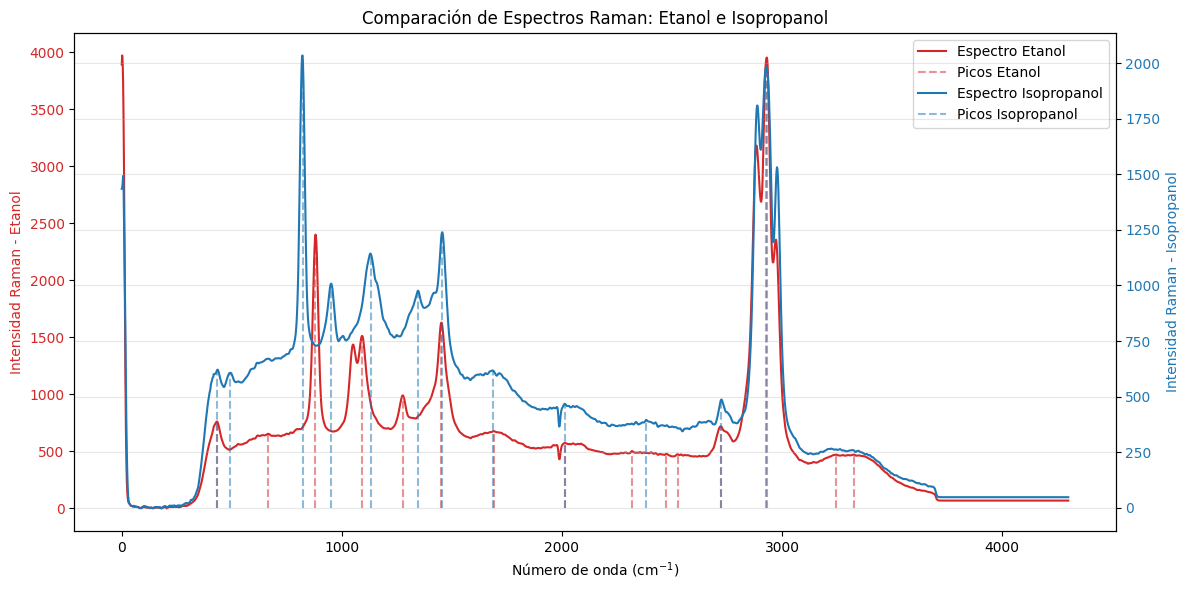

In [42]:
fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot Ethanol on the left y-axis
color1 = 'tab:red'
ax1.set_xlabel('Número de onda (cm$^{-1}$)')
ax1.set_ylabel('Intensidad Raman - Etanol', color=color1)
ax1.plot(etanol_clean.index, etanol_clean["Intensity"], color=color1, label='Espectro Etanol')
ax1.vlines(x=etanol_peaks.index, ymin=0, ymax=etanol_peaks["Peak_Intensity"], color=color1, linestyle='--', alpha=0.5, label='Picos Etanol')
ax1.tick_params(axis='y', labelcolor=color1)

# Create a second y-axis sharing the same x-axis
ax2 = ax1.twinx()

# Plot Isopropanol on the right y-axis
color2 = 'tab:blue'
ax2.set_ylabel('Intensidad Raman - Isopropanol', color=color2)
ax2.plot(isopropanol_clean.index, isopropanol_clean["Intensity"], color=color2, label='Espectro Isopropanol')
ax2.vlines(x=isopropanol_peaks.index, ymin=0, ymax=isopropanol_peaks["Peak_Intensity"], color=color2, linestyle='--', alpha=0.5, label='Picos Isopropanol')
ax2.tick_params(axis='y', labelcolor=color2)

# Add legends from both axes
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper right')

plt.title('Comparación de Espectros Raman: Etanol e Isopropanol')
plt.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

### **Referencias**

1. Cersoy, S., Rouchon, V., Belhadj, O., Cuisin, J., & Herbin, M. (2020).
*Noninvasive Fluid Identification: Potential of Micro-Raman Spectroscopy*.
**Collection Forum, 34**(1), 53–72.
https://doi.org/10.14351/0831-4985-34.1.53

2. PhysicsOpenLab (2022). Raman Spectra of Alcoholic Molecules. https://physicsopenlab.org/2022/01/20/raman-spectra-of-alcoholic-molecules/

3. ScanCoTec. Preguntas frecuentes (FAQ) sobre la espectroscopia Raman: teoría y uso. https://scancotec.com/blog/preguntas-frecuentes-faq-sobre-la-espectroscopia-raman-teoria-y-uso/

4. National Institute of Advanced Industrial Science and Technology (AIST). *Spectral Database for Organic Compounds (SDBSWeb): Ethanol, SDBS-1300; Raman spectrum SDBS-RM-01-00016*. https://sdbs.db.aist.go.jp/CompoundLanding.aspx?sdbsno=1300

5. National Institute of Advanced Industrial Science and Technology (AIST). *Spectral Database for Organic Compounds (SDBS): Raman spectrum of isopropanol.* https://sdbs.db.aist.go.jp/RamanSpectralView.aspx?fname=RM29&sdbsno=2149

